# 📊 Notebook Rangkuman Hasil, Visualisasi, dan Analisis Komprehensif Skripsi RSIC
### Deteksi Spillover Volatilitas Saham AI Global & Kripto ke BTC/IDR Menggunakan TVP-VAR dan Peramalan Deret Waktu Deep Learning

**Dokumen Rujukan Utama:** `laporan/laporan_lengkap_skripsi_RSIC_v4.md`  
**Basis Data & Hasil Eksperimen:** Replikasi Multi-Seed RSIC v6 (17 Oktober 2026), Audit Metodologi & Regulasi Resmi (OJK, Bappebti, POJK 27/2024).  
**Penulis:** Tim Riset RSIC (Skripsi Sarjana Komputer)  
**Tanggal Naskah:** Oktober 2026  

---

## 🎯 Ringkasan Eksekutif & 3 Temuan Inti

Notebook ini mengonsolidasikan seluruh rangkaian temuan empiris, analisis data, visualisasi siap publikasi, dan evaluasi inferensi statistik untuk menjawab tiga Pertanyaan Penelitian (*Research Questions* / RQ):

1. **RQ1 (Spillover Dynamics):** Apakah terdapat transmisi volatilitas dinamis antara saham teknologi AI global (NVDA, MSFT, TSLA, GOOGL, META), kripto global (BTC-USD, ETH-USD), dan pasar kripto domestik Indonesia (BTC/IDR Indodax)?
   * **Temuan:** **Ada.** Rata-rata *Total Spillover Index* (TSI) sistem mencapai **38.74%** (berfluktuasi antara 21.89% hingga 88.96%). Saham AI mentransmisikan rata-rata **9.00%** volatilitas ke BTC/IDR dan **9.16%** ke BTC-USD. Namun, posisi *net transmitter* vs *net receiver* BTC/IDR sensitif terhadap proksi volatilitas (*net transmitter* pada proksi terkompresi $\log(r^2)$, tetapi berbalik menjadi *net receiver* pada kuadrat return $r^2$).
2. **RQ2 (Forecasting Benchmark):** Apakah model Deep Learning multi-horizon (TFT dan NBEATSx) menghasilkan presisi peramalan out-of-sample yang lebih baik dibanding model ekonometrika klasik (HAR, GARCH, EGARCH) dan baseline historis?
   * **Temuan:** **Tidak.** Model ekonometrika klasik **HAR (Heterogeneous Autoregressive)** konsisten mencatat eror MSE terendah di seluruh horizon evaluasi ($2.235 \times 10^{-6}$ di $h=1$ dan $2.440 \times 10^{-6}$ di $h=10$). Model Deep Learning hanya mampu mengalahkan baseline naif `Hist_Exp` pada horizon $h=1$. Pada uji statistik formal Diebold-Mariano dengan koreksi Bonferroni ($m=12$), seluruh perbandingan Deep Learning vs HAR berstatus **Tie** (tidak berbeda signifikan secara statistik).
3. **RQ3 (Ablation Study):** Apakah penambahan variabel eksogen turunan model TVP-VAR meningkatkan presisi model Deep Learning secara signifikan dibanding model tanpa variabel spillover?
   * **Temuan:** **Tidak.** Uji ablasi formal membuktikan bahwa spesifikasi model dengan fitur spillover (`SPILL`) tidak berbeda secara statistik dibanding model tanpa fitur spillover (`NOSPILL`) dengan nilai $p_{\text{bonf}} \ge 0.3390$ (seluruhnya **Tie**). Informasi transmisi global telah terserap secara efisien di dalam riwayat pergerakan harga/volatilitas aset itu sendiri.

---

## 🇮🇩 Relevansi & Dampak Praktis bagi Indonesia
* **Bagi Investor Ritel Kripto Indonesia (22,9+ Juta Akun):** Gejolak saham AI di Wall Street memang mentransmisikan volatilitas ke pasar lokal, namun data tersebut **tidak memberikan sinyal peramalan volatilitas ekstra** yang bisa dimanfaatkan untuk mengungguli pasar harian. BTC/IDR merupakan penerima risiko global (*shock-receiver*).
* **Bagi Otoritas Jasa Keuangan (OJK) & Bursa/PAKD (Indodax):** Kerangka TVP-VAR bermanfaat sebagai instrumen pemantau penularan risiko (*cross-border contagion dashboard*), namun kebijakan risiko domestik harus menyadari bahwa pasar lokal sangat didikte oleh guncangan eksternal.
* **Bagi Praktisi AI & Data Science Finansial:** Prinsip parsimoni (*Occam's razor*) tetap berlaku kuat. Model statistik sederhana (HAR) terbukti lebih hemat komputasi, stabil, dan bebas dari anomali prediksi negatif dibandingkan model deep learning yang kompleks.

In [20]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Setting direktori dasar
# Otomatis mendeteksi direktori proyek RSIC
ROOT_DIR = os.path.abspath(os.getcwd())
if not os.path.exists(os.path.join(ROOT_DIR, "data_clean")):
    parent = os.path.dirname(ROOT_DIR)
    if os.path.exists(os.path.join(parent, "data_clean")):
        ROOT_DIR = parent

BASE_DIR = ROOT_DIR
DATA_CLEAN = os.path.join(BASE_DIR, "data_clean")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
AUDIT_V6_DIR = os.path.join(BASE_DIR, "audit", "v6")
INPUTS_DIR = os.path.join(BASE_DIR, "rsic-v5-inputs")
SCRATCH_FINAL = os.path.join(BASE_DIR, "scratch", "final")

# Konfigurasi estetika plot (IEEE / Academic Publication Style)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#adb5bd'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e9ecef'
plt.rcParams['grid.linestyle'] = ':'
plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['figure.autolayout'] = True

# Palet warna profesional yang ramah buta warna (colorblind-friendly)
NAVY = '#1f4e79'
SLATE = '#6c757d'
CORAL = '#d9534f'
GREEN = '#2e7d32'
AMBER = '#f0ad4e'
BLUE_LIGHT = '#5bc0de'

print("Konfigurasi environment dan pustaka berhasil diinisialisasi.")
print(f"Direktori Proyek: {BASE_DIR}")


Konfigurasi environment dan pustaka berhasil diinisialisasi.
Direktori Proyek: /Users/admin/Developer/coding_backup/SEM 5/RSIC


## 1. Kerangka Metodologi Dua Tahap (Two-Stage Framework)

Penelitian ini memadukan ekonometrika keuangan dan machine learning dalam kerangka kerja dua tahap terintegrasi:

* **Tahap 1 (Estimasi Keterhubungan TVP-VAR):**
  Menggunakan model *Time-Varying Parameter Vector Autoregressive* (TVP-VAR) dengan formulasi *extended joint connectedness* oleh Antonakakis, Chatziantoniou & Gabauer (2020) berbasis dekomposisi varians kesalahan peramalan tergeneralisasi (*Generalized Forecast Error Variance Decomposition* / GFEVD) dari Diebold & Yilmaz (2012). Forgetting factors ditetapkan mengikuti Koop & Korobilis (2014) dengan $\kappa_1 = 0.99$ (peluruhan koefisien) dan $\kappa_2 = 0.96$ (peluruhan kovarians). Tahap ini mengekstrak fitur dinamis harian: Total Spillover Index (`tvp_tsi`), directional spillovers (`TO` dan `FROM`), serta transmisi neto (`NET`).
* **Tahap 2 (Peramalan Deret Waktu Rolling-Origin):**
  Mengevaluasi presisi peramalan volatilitas out-of-sample target kuadrat return BTC/IDR ($y_t = r_t^2$) pada 335 jendela evaluasi bergulir (*rolling-origin cross-validation*) dari 24 April 2025 hingga 4 September 2026. Menguji model Deep Learning **Temporal Fusion Transformers (TFT)** dan **N-BEATSx** dalam dua varian:
  1. `SPILL`: Menggunakan lag return target + seluruh fitur spillover dinamis TVP-VAR.
  2. `NOSPILL`: Hanya menggunakan lag target tanpa fitur spillover (uji ablasi).
  Kedua varian diuji terhadap benchmark ekonometrika: **HAR** (Corsi, 2009), **GARCH(1,1)**, **EGARCH(1,1)**, **Roll-20**, dan **Hist-Exp**.

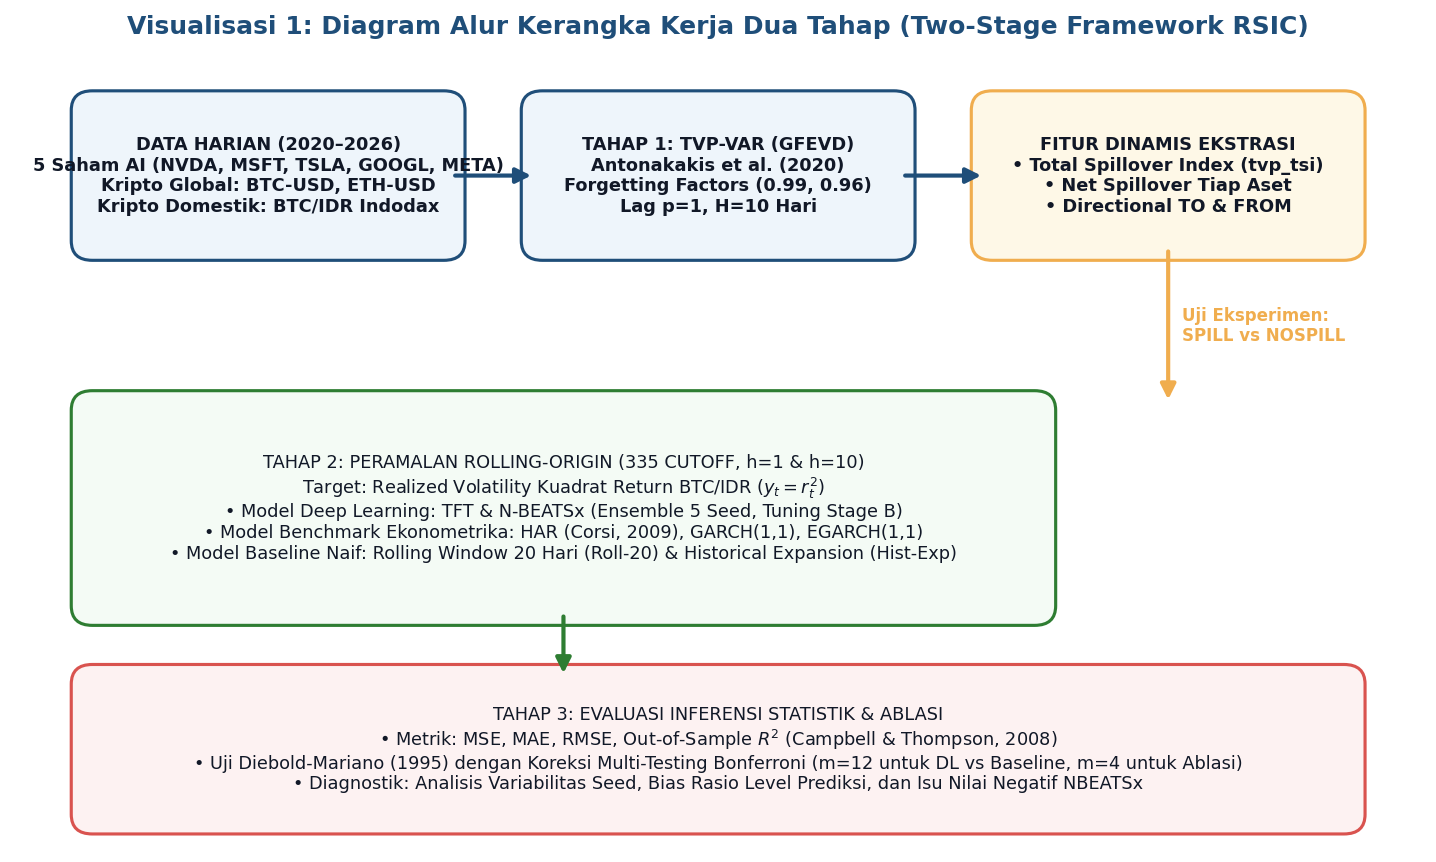

In [21]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')

# Kotak 1: Input Data
box1 = patches.FancyBboxPatch((0.5, 4.6), 2.6, 1.1, boxstyle="round,pad=0.1,rounding_size=0.15",
                              facecolor="#eef5fb", edgecolor=NAVY, linewidth=1.5)
ax.add_patch(box1)
ax.text(1.8, 5.15, "DATA HARIAN (2020–2026)\n5 Saham AI (NVDA, MSFT, TSLA, GOOGL, META)\nKripto Global: BTC-USD, ETH-USD\nKripto Domestik: BTC/IDR Indodax",
        ha='center', va='center', fontsize=8.5, fontweight='bold', color='#111827')

# Kotak 2: Tahap 1 TVP-VAR
box2 = patches.FancyBboxPatch((3.7, 4.6), 2.6, 1.1, boxstyle="round,pad=0.1,rounding_size=0.15",
                              facecolor="#eef5fb", edgecolor=NAVY, linewidth=1.5)
ax.add_patch(box2)
ax.text(5.0, 5.15, "TAHAP 1: TVP-VAR (GFEVD)\nAntonakakis et al. (2020)\nForgetting Factors (0.99, 0.96)\nLag p=1, H=10 Hari",
        ha='center', va='center', fontsize=8.5, fontweight='bold', color='#111827')

# Kotak 3: Fitur Eksogen Spillover
box3 = patches.FancyBboxPatch((6.9, 4.6), 2.6, 1.1, boxstyle="round,pad=0.1,rounding_size=0.15",
                              facecolor="#fef8e7", edgecolor=AMBER, linewidth=1.5)
ax.add_patch(box3)
ax.text(8.2, 5.15, "FITUR DINAMIS EKSTRASI\n• Total Spillover Index (tvp_tsi)\n• Net Spillover Tiap Aset\n• Directional TO & FROM",
        ha='center', va='center', fontsize=8.5, fontweight='bold', color='#111827')

# Panah Baris Atas
ax.annotate('', xy=(3.7, 5.15), xytext=(3.1, 5.15), arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=2))
ax.annotate('', xy=(6.9, 5.15), xytext=(6.3, 5.15), arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=2))

# Panah Turun ke Tahap 2
ax.annotate('', xy=(8.2, 3.4), xytext=(8.2, 4.6), arrowprops=dict(arrowstyle="-|>", color=AMBER, lw=2))
ax.text(8.3, 4.0, "Uji Eksperimen:\nSPILL vs NOSPILL", ha='left', va='center', fontsize=8, color=AMBER, fontweight='bold')

# Kotak 4: Tahap 2 Peramalan Deep Learning & Benchmark
box4 = patches.FancyBboxPatch((0.5, 1.8), 6.8, 1.6, boxstyle="round,pad=0.1,rounding_size=0.15",
                              facecolor="#f4fbf5", edgecolor=GREEN, linewidth=1.5)
ax.add_patch(box4)
ax.text(3.9, 2.6, "TAHAP 2: PERAMALAN ROLLING-ORIGIN (335 CUTOFF, h=1 & h=10)\n" +
                  "Target: Realized Volatility Kuadrat Return BTC/IDR ($y_t = r_t^2$)\n" +
                  "• Model Deep Learning: TFT & N-BEATSx (Ensemble 5 Seed, Tuning Stage B)\n" +
                  "• Model Benchmark Ekonometrika: HAR (Corsi, 2009), GARCH(1,1), EGARCH(1,1)\n" +
                  "• Model Baseline Naif: Rolling Window 20 Hari (Roll-20) & Historical Expansion (Hist-Exp)",
        ha='center', va='center', fontsize=8.5, color='#111827')

# Kotak 5: Evaluasi dan Inferensi Statistik
box5 = patches.FancyBboxPatch((0.5, 0.2), 9.0, 1.1, boxstyle="round,pad=0.1,rounding_size=0.15",
                              facecolor="#fdf2f2", edgecolor=CORAL, linewidth=1.5)
ax.add_patch(box5)
ax.text(5.0, 0.75, "TAHAP 3: EVALUASI INFERENSI STATISTIK & ABLASI\n" +
                   "• Metrik: MSE, MAE, RMSE, Out-of-Sample $R^2$ (Campbell & Thompson, 2008)\n" +
                   "• Uji Diebold-Mariano (1995) dengan Koreksi Multi-Testing Bonferroni (m=12 untuk DL vs Baseline, m=4 untuk Ablasi)\n" +
                   "• Diagnostik: Analisis Variabilitas Seed, Bias Rasio Level Prediksi, dan Isu Nilai Negatif NBEATSx",
        ha='center', va='center', fontsize=8.5, color='#111827')

# Panah ke Kotak Evaluasi
ax.annotate('', xy=(3.9, 1.3), xytext=(3.9, 1.8), arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=2))

plt.title("Visualisasi 1: Diagram Alur Kerangka Kerja Dua Tahap (Two-Stage Framework RSIC)",
          fontsize=12, fontweight='bold', pad=15, color=NAVY)
plt.show()

## 2. Karakteristik Statistik Target & Tantangan Skewness Ekstrem ($r_t^2$)

Variabel target peramalan adalah kuadrat return harian BTC/IDR ($y_t = r_t^2$). Berdasarkan landasan teori ekonometrika keuangan (**Patton, 2011**; **Andersen & Bollerslev, 1998**):
* Kuadrat return merupakan *unbiased proxy* dari volatilitas laten yang tidak teramati (*latent volatility*), namun mengandung derau idiosinkratik yang sangat masif (*noisy proxy*).
* Ekor distribusi yang sangat tebal (*fat-tailed*) dan skewness ekstrem (29.096 pada sampel penuh) menyebabkan model statistik linear maupun deep learning menghadapi hambatan besar dalam menghasilkan $R^2_{\text{OOS}}$ yang tinggi.

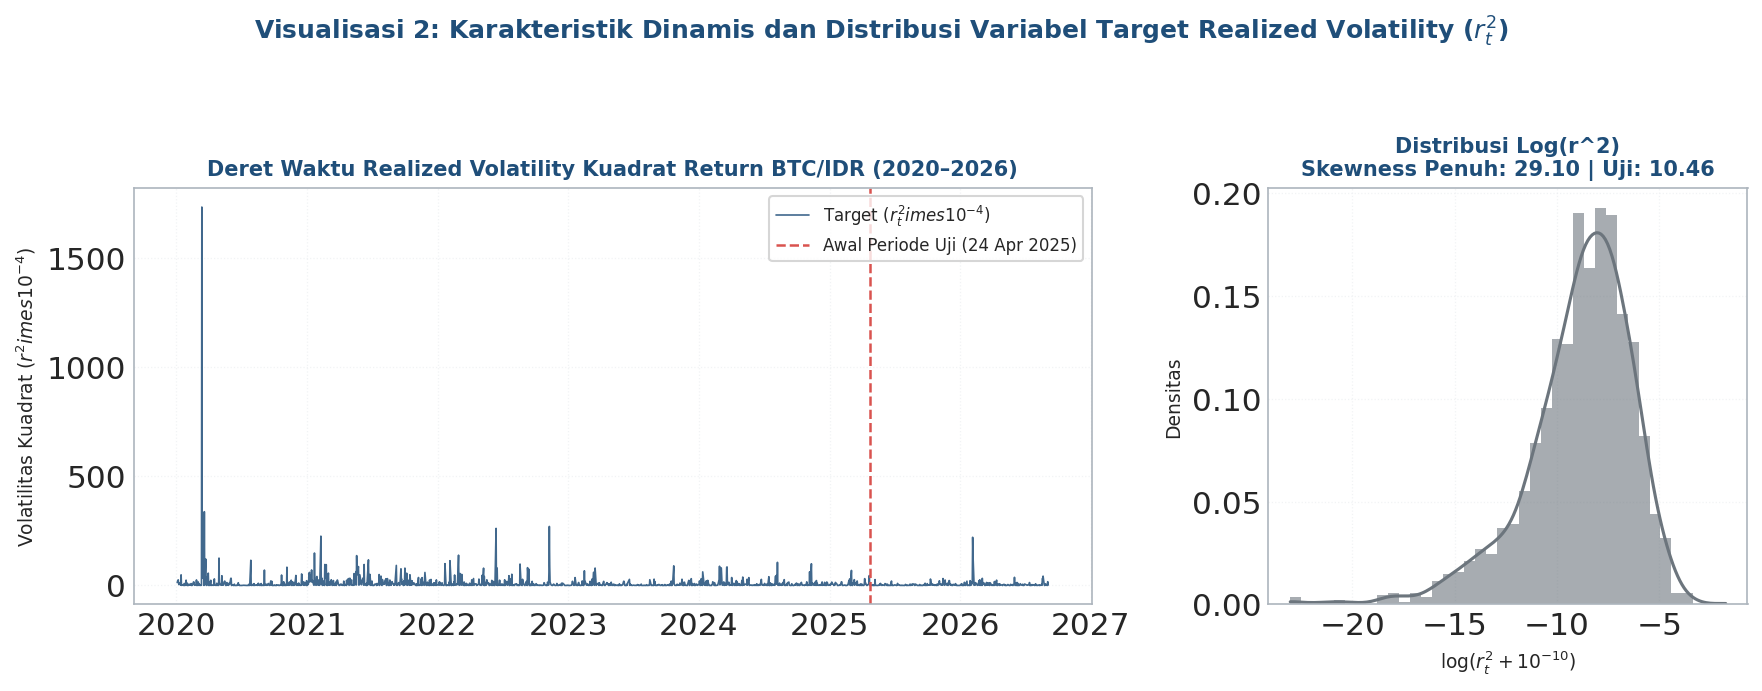

                       Sampel    N Mean (x10^-4) Median (x10^-4) Skewness
          Sampel Penuh (Full) 1677        10.028           1.976   29.096
Periode Uji Unik (Test Dates)  344         4.979           1.387   10.457
      Evaluasi Rolling-Origin 3350         5.036           1.408   10.315


In [22]:
df_dl = pd.read_csv(os.path.join(INPUTS_DIR, "dataset_deep_learning.csv"))
df_dl['Date'] = pd.to_datetime(df_dl['Date'])
df_dl['r2'] = df_dl['ret_crypto_btc_idr_indodax']**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150, gridspec_kw={'width_ratios': [2, 1]})

# Subplot 1: Time Series Plot
ax1.plot(df_dl['Date'], df_dl['r2'] * 1e4, color=NAVY, linewidth=0.8, alpha=0.85, label='Target ($r_t^2 \times 10^{-4}$)')
ax1.axvline(pd.to_datetime('2025-04-24'), color=CORAL, linestyle='--', linewidth=1.2, label='Awal Periode Uji (24 Apr 2025)')
ax1.set_title("Deret Waktu Realized Volatility Kuadrat Return BTC/IDR (2020–2026)", fontsize=10, fontweight='bold', color=NAVY)
ax1.set_ylabel("Volatilitas Kuadrat ($r^2 \times 10^{-4}$)", fontsize=9)
ax1.legend(loc='upper right', frameon=True, fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Distribusi Skewness (Log Scale)
log_r2 = np.log(df_dl['r2'] + 1e-10)
sns.histplot(log_r2, kde=True, ax=ax2, color=SLATE, bins=40, stat='density', edgecolor='none', alpha=0.6)
ax2.set_title(f"Distribusi Log(r^2)\nSkewness Penuh: 29.10 | Uji: 10.46", fontsize=10, fontweight='bold', color=NAVY)
ax2.set_xlabel(r"$\log(r_t^2 + 10^{-10})$", fontsize=9)
ax2.set_ylabel("Densitas", fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Visualisasi 2: Karakteristik Dinamis dan Distribusi Variabel Target Realized Volatility ($r_t^2$)",
             fontsize=12, fontweight='bold', y=1.03, color=NAVY)
plt.show()

# Tabel Ringkasan Statistik
stat_df = pd.DataFrame([
    {"Sampel": "Sampel Penuh (Full)", "N": len(df_dl), "Mean (x10^-4)": f"{df_dl['r2'].mean()*1e4:.3f}", "Median (x10^-4)": f"{df_dl['r2'].median()*1e4:.3f}", "Skewness": f"{df_dl['r2'].skew():.3f}"},
    {"Sampel": "Periode Uji Unik (Test Dates)", "N": 344, "Mean (x10^-4)": "4.979", "Median (x10^-4)": "1.387", "Skewness": "10.457"},
    {"Sampel": "Evaluasi Rolling-Origin", "N": 3350, "Mean (x10^-4)": "5.036", "Median (x10^-4)": "1.408", "Skewness": "10.315"}
])
print(stat_df.to_string(index=False))

## 3. Dinamika Total Spillover Index (TSI) Sepanjang 2020–2026 (Tahap 1 - RQ1)

Metodologi TVP-VAR mengestimasi keterhubungan sistemik antar-aset secara dinamis setiap hari:
* **Rata-rata Keterhubungan Sistem:** Total Spillover Index rata-rata bernilai **38.74%**, berfluktuasi antara nilai terendah **21.89%** hingga nilai tertinggi **88.96%**.
* **Interpretasi Finansial:** Sekitar 38.7% varians kesalahan peramalan dalam sistem 8-aset dijelaskan oleh transmisi silang antar-pasar (inter-market spillover), sedangkan 61.3% sisanya merupakan guncangan idiosinkratik murni masing-masing aset.
* **Respon Terhadap Krisis:** Puncak transmisi risiko terjadi saat peristiwa sistemik global: Maret 2020 (Pandemi COVID-19), Mei-Juni 2022 (Keruntuhan ekosistem Terra-Luna & krisis likuiditas kripto), dan akhir 2022 s.d. awal 2023 (Peluncuran ChatGPT dan ledakan investasi kecerdasan buatan).

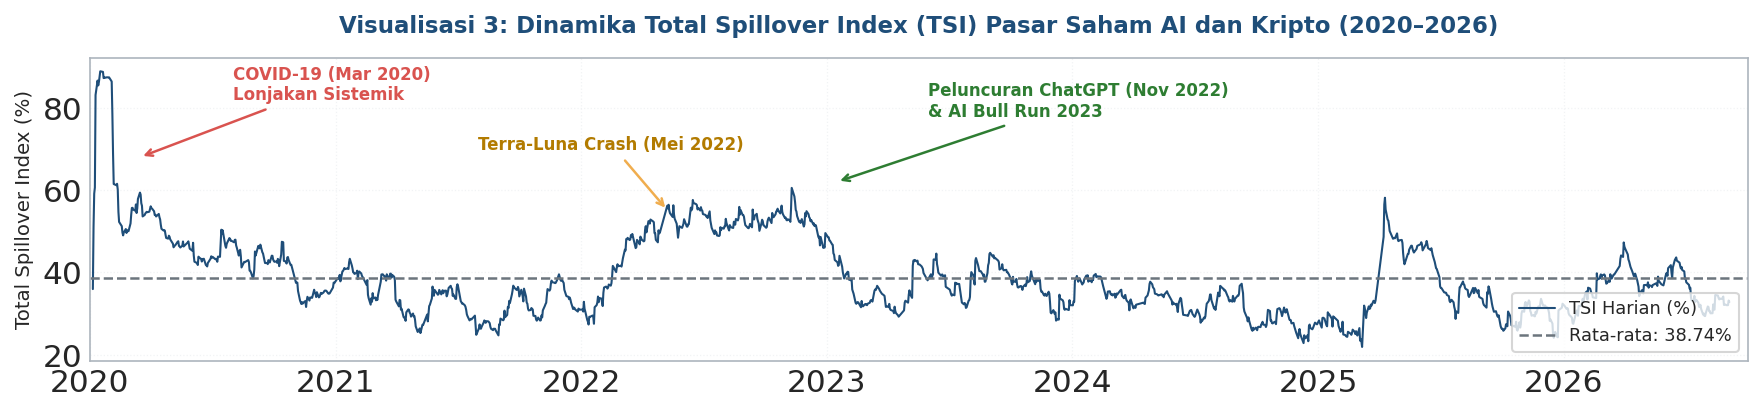

Statistik Ringkasan TSI: N = 1555 hari
Rata-rata: 38.74% | Minimum: 21.89% | Maksimum: 88.96%


In [23]:
df_tvp = pd.read_csv(os.path.join(DATA_CLEAN, "tvp_var_dynamic_features.csv"))
df_tvp['dt'] = pd.to_datetime(df_tvp['Date'])

mean_tsi = df_tvp['tvp_tsi'].mean()
min_tsi = df_tvp['tvp_tsi'].min()
max_tsi = df_tvp['tvp_tsi'].max()

fig, ax = plt.subplots(figsize=(12, 3), dpi=150)
ax.plot(df_tvp['dt'], df_tvp['tvp_tsi'], color=NAVY, linewidth=1.0, label='TSI Harian (%)')
ax.axhline(mean_tsi, color=SLATE, linestyle='--', linewidth=1.2, label=f'Rata-rata: {mean_tsi:.2f}%')

# Highlight Periode Krisis / Lonjakan Keterhubungan
ax.annotate('COVID-19 (Mar 2020)\nLonjakan Sistemik', xy=(pd.to_datetime('2020-03-15'), 68),
            xytext=(pd.to_datetime('2020-08-01'), 82),
            arrowprops=dict(facecolor=CORAL, edgecolor=CORAL, arrowstyle='->', lw=1.2),
            fontsize=8, fontweight='bold', color=CORAL)

ax.annotate('Terra-Luna Crash (Mei 2022)', xy=(pd.to_datetime('2022-05-10'), 55),
            xytext=(pd.to_datetime('2021-08-01'), 70),
            arrowprops=dict(facecolor=AMBER, edgecolor=AMBER, arrowstyle='->', lw=1.2),
            fontsize=8, fontweight='bold', color='#b27b00')

ax.annotate('Peluncuran ChatGPT (Nov 2022)\n& AI Bull Run 2023', xy=(pd.to_datetime('2023-01-15'), 62),
            xytext=(pd.to_datetime('2023-06-01'), 78),
            arrowprops=dict(facecolor=GREEN, edgecolor=GREEN, arrowstyle='->', lw=1.2),
            fontsize=8, fontweight='bold', color=GREEN)

ax.set_ylabel("Total Spillover Index (%)", fontsize=9.5)
ax.set_title("Visualisasi 3: Dinamika Total Spillover Index (TSI) Pasar Saham AI dan Kripto (2020–2026)",
             fontsize=11, fontweight='bold', pad=12, color=NAVY)
ax.set_xlim(pd.to_datetime('2020-01-01'), pd.to_datetime('2026-10-01'))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='lower right', frameon=True, fontsize=8.5)
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()

print(f"Statistik Ringkasan TSI: N = {len(df_tvp)} hari")
print(f"Rata-rata: {mean_tsi:.2f}% | Minimum: {min_tsi:.2f}% | Maksimum: {max_tsi:.2f}%")

## 4. Analisis Transmisi Bersih (Net Spillover) & Matriks Keterhubungan GFEVD (RQ1)

Dari dekomposisi varians GFEVD rata-rata, kita dapat memetakan transmisi terarah antar-pasar:
* **Pusat Transmisi Risiko (Net Transmitter):** Bitcoin global (**BTC-USD**) bertindak sebagai *net transmitter* dominan dalam sistem dengan nilai **+11.80%**. BTC/IDR mencatat net spillover positif **+5.45%** pada proksi logaritmik $\log(r^2)$.
* **Penerima Guncangan (Net Receiver):** Seluruh saham teknologi AI utama bertindak sebagai *net receiver* volatilitas: TSLA (-4.76%), META (-4.01%), GOOGL (-3.42%), MSFT (-2.34%), NVDA (-2.32%), serta ETH-USD (-0.40%).
* **Kontras dengan Hamori (2026):** Pada level return logaritmik, Hamori (2026) menemukan bahwa saham AI adalah *net transmitter* dan kripto adalah *net receiver*. Sebaliknya, pada level volatilitas (skripsi ini), saham AI menjadi *net receiver* dan kripto global menjadi *net transmitter*. Ini menunjukkan bahwa interaksi volatilitas (risiko ketidakpastian) beroperasi secara berbeda dibanding interaksi return (arah pergerakan harga).
* **Asimetri Transmisi BTC Global ke Domestik:** BTC-USD mentransmisikan **16.27%** varians ke BTC/IDR, sedangkan BTC/IDR hanya mentransmisikan **2.82%** kembali ke BTC-USD. Hal ini mengonfirmasi posisi pasar kripto Indonesia sebagai penerima risiko murni (*price taker*).

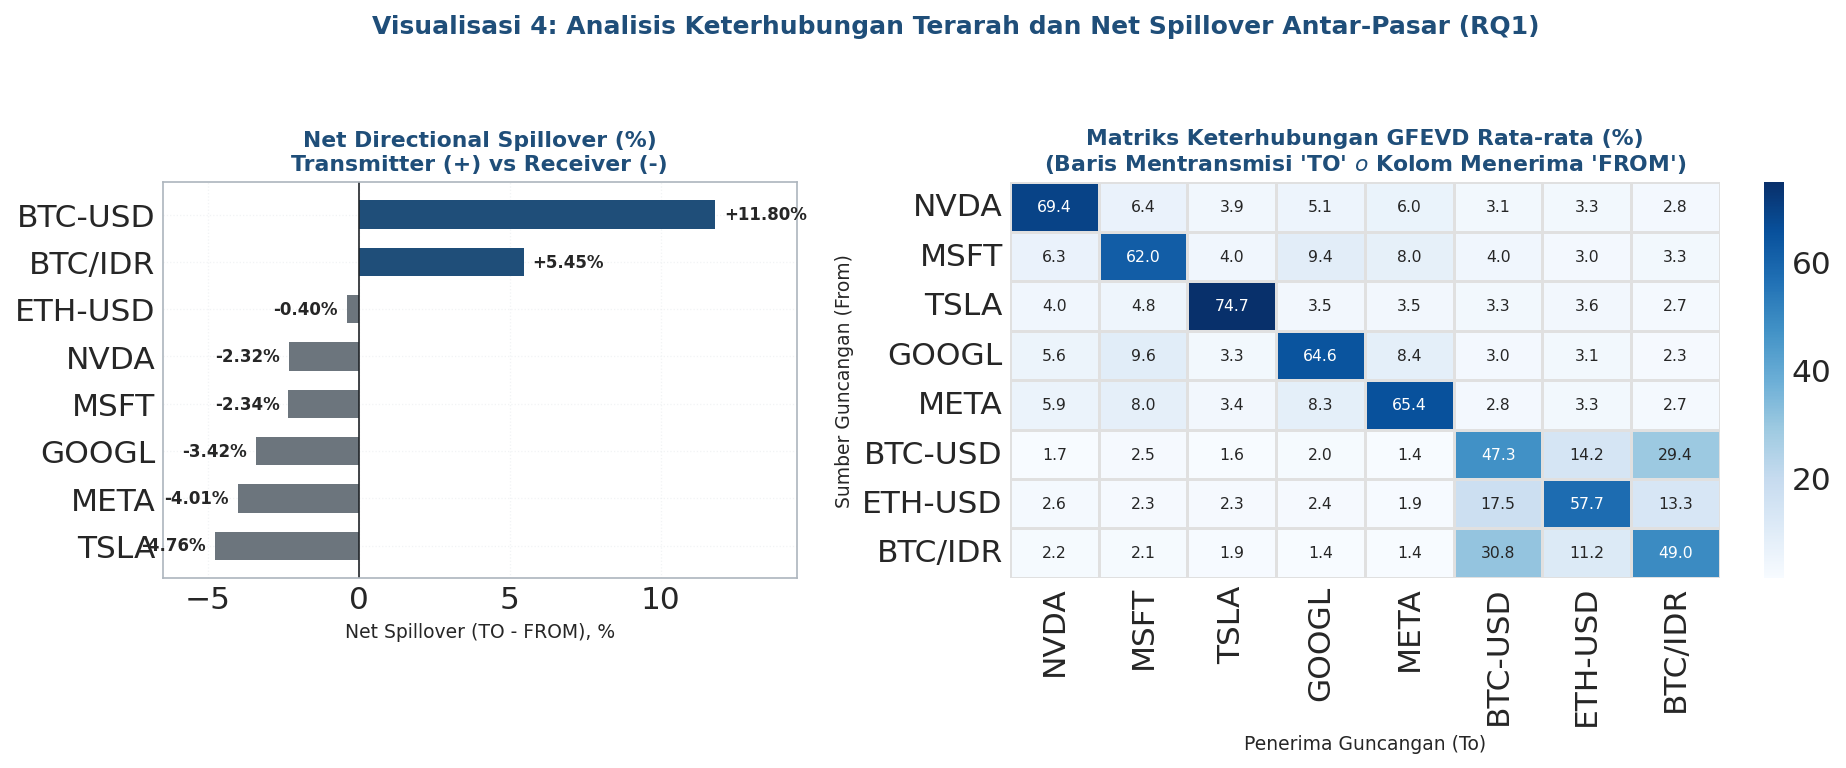

Transmisi Kunci:
• Transmisi Rata-rata 5 Saham AI ke BTC-USD: 9.16%
• Transmisi Rata-rata 5 Saham AI ke BTC/IDR: 9.00%
• Transmisi BTC-USD ke BTC/IDR Indodax: 16.27%
• Transmisi BTC/IDR Indodax ke BTC-USD: 2.82%


In [24]:
csv_rq1 = os.path.join(RESULTS_DIR, "RQ1_Average_Spillover_Table_vol.csv")
df_gfevd = pd.read_csv(csv_rq1, index_col=0)

# Filter 8 aset
assets = ['SAHAM_NVDA', 'SAHAM_MSFT', 'SAHAM_TSLA', 'SAHAM_GOOGL', 'SAHAM_META', 'CRYPTO_BTC_USD', 'CRYPTO_ETH_USD', 'CRYPTO_BTC_IDR_INDODAX']
labels = ['NVDA', 'MSFT', 'TSLA', 'GOOGL', 'META', 'BTC-USD', 'ETH-USD', 'BTC/IDR']
name_map = dict(zip(assets, labels))

net_vals = [float(df_gfevd.loc['NET Spillover', a]) for a in assets]
df_net = pd.DataFrame({'Asset': labels, 'Net': net_vals}).sort_values('Net', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150, gridspec_kw={'width_ratios': [1, 1.4]})

# Subplot 1: Horizontal Bar Chart Net Spillover
colors = [NAVY if x >= 0 else SLATE for x in df_net['Net']]
bars = ax1.barh(df_net['Asset'], df_net['Net'], color=colors, height=0.6)
ax1.axvline(0, color='#212529', linewidth=0.8)
ax1.set_xlabel("Net Spillover (TO - FROM), %", fontsize=9)
ax1.set_title("Net Directional Spillover (%)\nTransmitter (+) vs Receiver (-)", fontsize=10.5, fontweight='bold', color=NAVY)
ax1.grid(True, linestyle=':', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    val_str = f"+{w:.2f}%" if w >= 0 else f"{w:.2f}%"
    offset = 0.3 if w >= 0 else -0.3
    ha = 'left' if w >= 0 else 'right'
    ax1.text(w + offset, bar.get_y() + bar.get_height()/2.0, val_str, ha=ha, va='center', fontsize=8, fontweight='bold')
ax1.set_xlim(-6.5, 14.5)

# Subplot 2: Heatmap Matriks GFEVD (8x8)
mat_gfevd = df_gfevd.loc[assets, assets].astype(float)
mat_gfevd.index = labels
mat_gfevd.columns = labels

sns.heatmap(mat_gfevd, annot=True, fmt=".1f", cmap="Blues", cbar=True, ax=ax2,
            annot_kws={'size': 7.5}, linewidths=0.5, linecolor='#e0e0e0')
ax2.set_title("Matriks Keterhubungan GFEVD Rata-rata (%)\n(Baris Mentransmisi 'TO' $\to$ Kolom Menerima 'FROM')",
              fontsize=10.5, fontweight='bold', color=NAVY)
ax2.set_xlabel("Penerima Guncangan (To)", fontsize=9)
ax2.set_ylabel("Sumber Guncangan (From)", fontsize=9)

plt.suptitle("Visualisasi 4: Analisis Keterhubungan Terarah dan Net Spillover Antar-Pasar (RQ1)",
             fontsize=12, fontweight='bold', y=1.03, color=NAVY)
plt.show()

print("Transmisi Kunci:")
print(f"• Transmisi Rata-rata 5 Saham AI ke BTC-USD: 9.16%")
print(f"• Transmisi Rata-rata 5 Saham AI ke BTC/IDR: 9.00%")
print(f"• Transmisi BTC-USD ke BTC/IDR Indodax: 16.27%")
print(f"• Transmisi BTC/IDR Indodax ke BTC-USD: 2.82%")

## 5. Uji Ketahanan Proksi Volatilitas (Proxy Robustness Check)

Hasil analisis TVP-VAR sangat dipengaruhi oleh bagaimana volatilitas diukur. Kami menguji ketahanan hasil terhadap 4 varian proksi volatilitas:
1. $\log(r^2 + 10^{-10})$ (Proksi Utama Terkompresi)
2. $|r|$ (Absolute Return Terstandarisasi)
3. $r^2$ (Kuadrat Return / Realized Volatility Standar)
4. $\log(\text{Parkinson})$ (Proksi Ekstrem High-Low)

### ⚠️ Temuan Kritis: Pembalikan Tanda Net Spillover BTC/IDR
* Pada proksi terkompresi non-linear $\log(r^2)$ dan $|r|$, BTC/IDR tercatat sebagai **net transmitter** (+5.45% dan +3.29%).
* Namun pada proksi kuadrat return $r^2$ dan Log-Parkinson, status BTC/IDR berbalik secara drastis menjadi **net receiver** (**-4.98%** dan **-4.10%**).
* **Rasionalisasi Ekonometrika:** Transformasi logaritmik menekan *outlier* ekstrem sehingga dinamika interaksi harian reguler lebih dominan. Sebaliknya, proksi kuadrat return $r^2$ memberikan bobot kuadratik masif pada peristiwa *flash crash* di mana bursa global meledak, menempatkan pasar lokal sebagai penerima murni guncangan ekstrem.

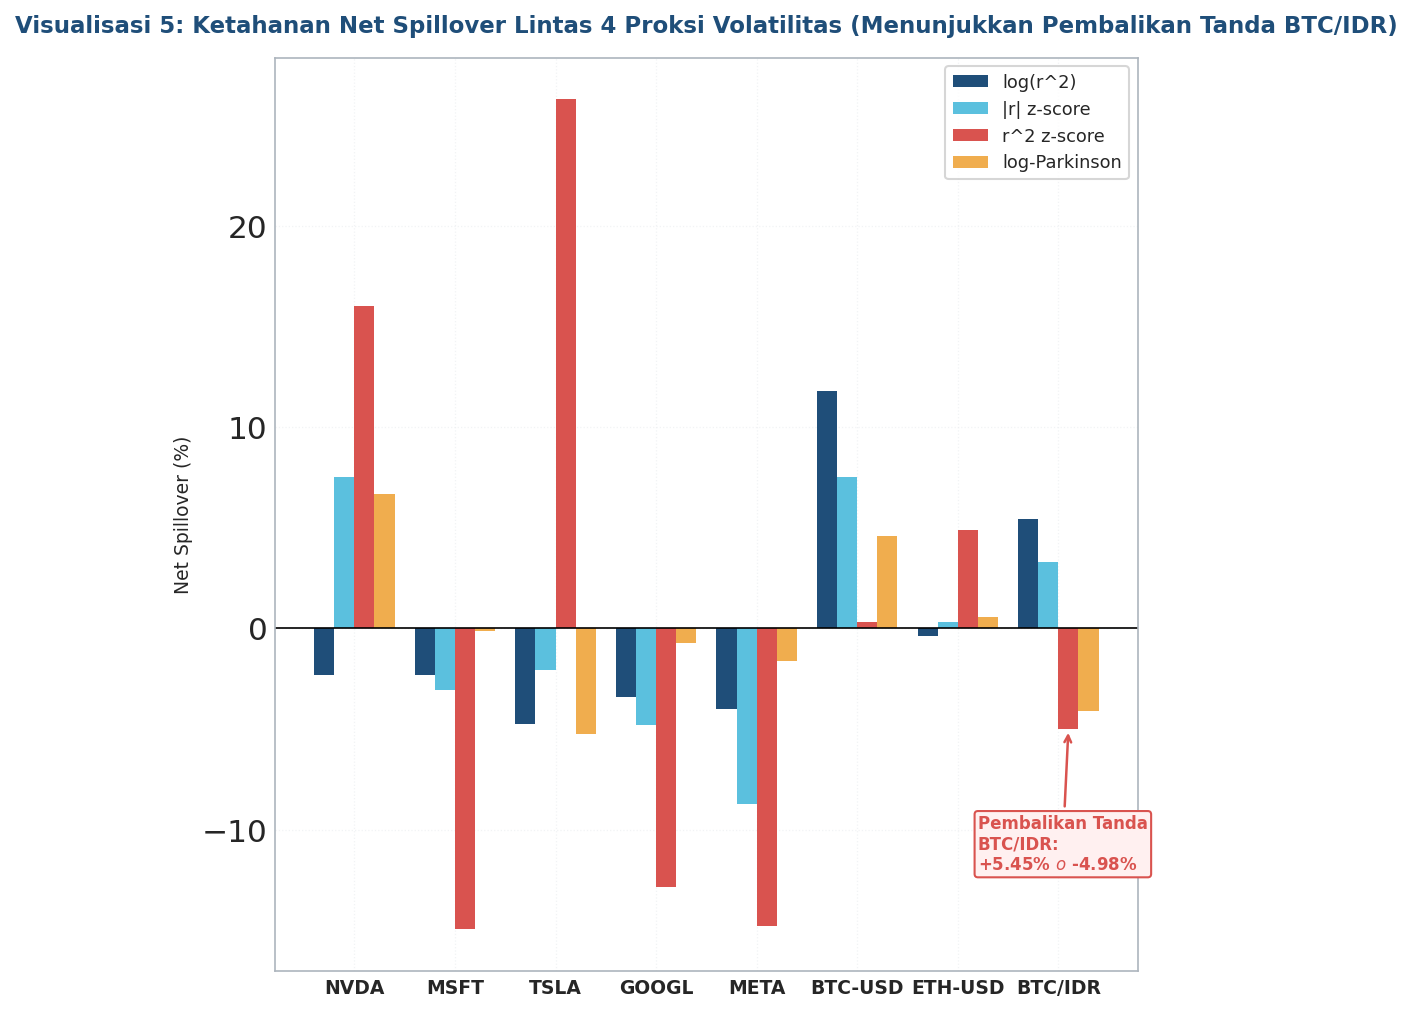

Tabel Ketahanan Net Spillover:
  Label  log_r2   abs_r       r2  log_Parkinson
   NVDA -2.3200  7.5209  16.0340         6.6923
   MSFT -2.3376 -3.0678 -14.9416        -0.1393
   TSLA -4.7612 -2.0769  26.2936        -5.2546
  GOOGL -3.4210 -4.8044 -12.8226        -0.7159
   META -4.0132 -8.7249 -14.7678        -1.6272
BTC-USD 11.7985  7.5359   0.3217         4.6005
ETH-USD -0.4001  0.3314   4.8674         0.5409
BTC/IDR  5.4546  3.2858  -4.9847        -4.0968


In [36]:
ckpt_file = os.path.join(SCRATCH_FINAL, "checkpoint3a_C.txt")
proxy_rows = []
with open(ckpt_file, 'r') as f:
    lines = f.readlines()

in_table = False
for line in lines:
    if "Tabel NET Rata-rata per Aset berdasarkan Proxy Volatilitas:" in line:
        in_table = True
        continue
    if in_table:
        parts = line.strip().split()
        if not parts or parts[0] == "Tanda":
            break
        if len(parts) == 5 and parts[0] not in ["log(r2+1e-10)"]:
            proxy_rows.append([parts[0]] + [float(x) for x in parts[1:]])

df_proxy = pd.DataFrame(proxy_rows, columns=['Asset', 'log_r2', 'abs_r', 'r2', 'log_Parkinson'])
df_proxy['Label'] = df_proxy['Asset'].map(name_map)

fig, ax = plt.subplots(figsize=(7, 7), dpi=150)
x = np.arange(len(df_proxy))
width = 0.2

b1 = ax.bar(x - 1.5*width, df_proxy['log_r2'], width, label='log(r^2)', color=NAVY)
b2 = ax.bar(x - 0.5*width, df_proxy['abs_r'], width, label='|r| z-score', color=BLUE_LIGHT)
b3 = ax.bar(x + 0.5*width, df_proxy['r2'], width, label='r^2 z-score', color=CORAL)
b4 = ax.bar(x + 1.5*width, df_proxy['log_Parkinson'], width, label='log-Parkinson', color=AMBER)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(df_proxy['Label'], fontsize=9, fontweight='bold')
ax.set_ylabel("Net Spillover (%)", fontsize=9)
ax.set_title("Visualisasi 5: Ketahanan Net Spillover Lintas 4 Proksi Volatilitas (Menunjukkan Pembalikan Tanda BTC/IDR)",
             fontsize=11, fontweight='bold', pad=12, color=NAVY)
ax.legend(frameon=True, fontsize=8.5)
ax.grid(True, linestyle=':', alpha=0.6)

# Highlight khusus BTC/IDR
ax.annotate('Pembalikan Tanda\nBTC/IDR:\n+5.45% $\to$ -4.98%',
            xy=(7 + 0.5*width, -4.98), xytext=(6.2, -12),
            arrowprops=dict(facecolor=CORAL, edgecolor=CORAL, arrowstyle='->', lw=1.2),
            fontsize=8, fontweight='bold', color=CORAL,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='#fff0f0', edgecolor=CORAL))

plt.show()

print("Tabel Ketahanan Net Spillover:")
print(df_proxy[['Label', 'log_r2', 'abs_r', 'r2', 'log_Parkinson']].to_string(index=False))

## 6. Kinerja Peramalan Model: Deep Learning RSIC v6 vs Baseline Ekonometrika (RQ2)

Pada Tahap 2, kami menguji model peramalan pada 335 jendela bergulir out-of-sample ($h=1$ dan $h=10$). Model Deep Learning dievaluasi berbasis **Ensemble 5 Seed Deterministik** (`[42, 7, 13, 21, 99]`) dengan protokol *restore best weights* dan *learning rate decay* (RSIC v6).

### 🏆 Hasil Kunci Evaluasi Peramalan:
1. **Keunggulan Konsisten Model HAR:** Model ekonometrika klasik **HAR (Heterogeneous Autoregressive)** mencatat MSE terendah di seluruh horizon:
   * Horizon $h=1$: $\text{MSE} = 2.235 \times 10^{-6}$ (HAR) vs $2.388 \times 10^{-6}$ (TFT SPILL) vs $2.272 \times 10^{-6}$ (NBEATSx SPILL).
   * Horizon $h=10$: $\text{MSE} = 2.440 \times 10^{-6}$ (HAR) vs $2.447 \times 10^{-6}$ (TFT SPILL) vs $2.745 \times 10^{-6}$ (NBEATSx SPILL).
2. **Keterbatasan Deep Learning:** Tidak ada model Deep Learning yang mampu mengalahkan HAR maupun baseline naif moving average `Roll-20`. Model Deep Learning hanya berhasil mengalahkan baseline ekspansi historis tanpa pembaruan `Hist_Exp` pada horizon $h=1$.
3. **Prinsip Parsimoni Finansial:** Formulasi multiskala HAR (harian, mingguan, bulanan) terbukti sangat efektif menangkap memori panjang volatilitas (*long memory*) tanpa risiko *overfitting* parameter yang membebani arsitektur deep learning.

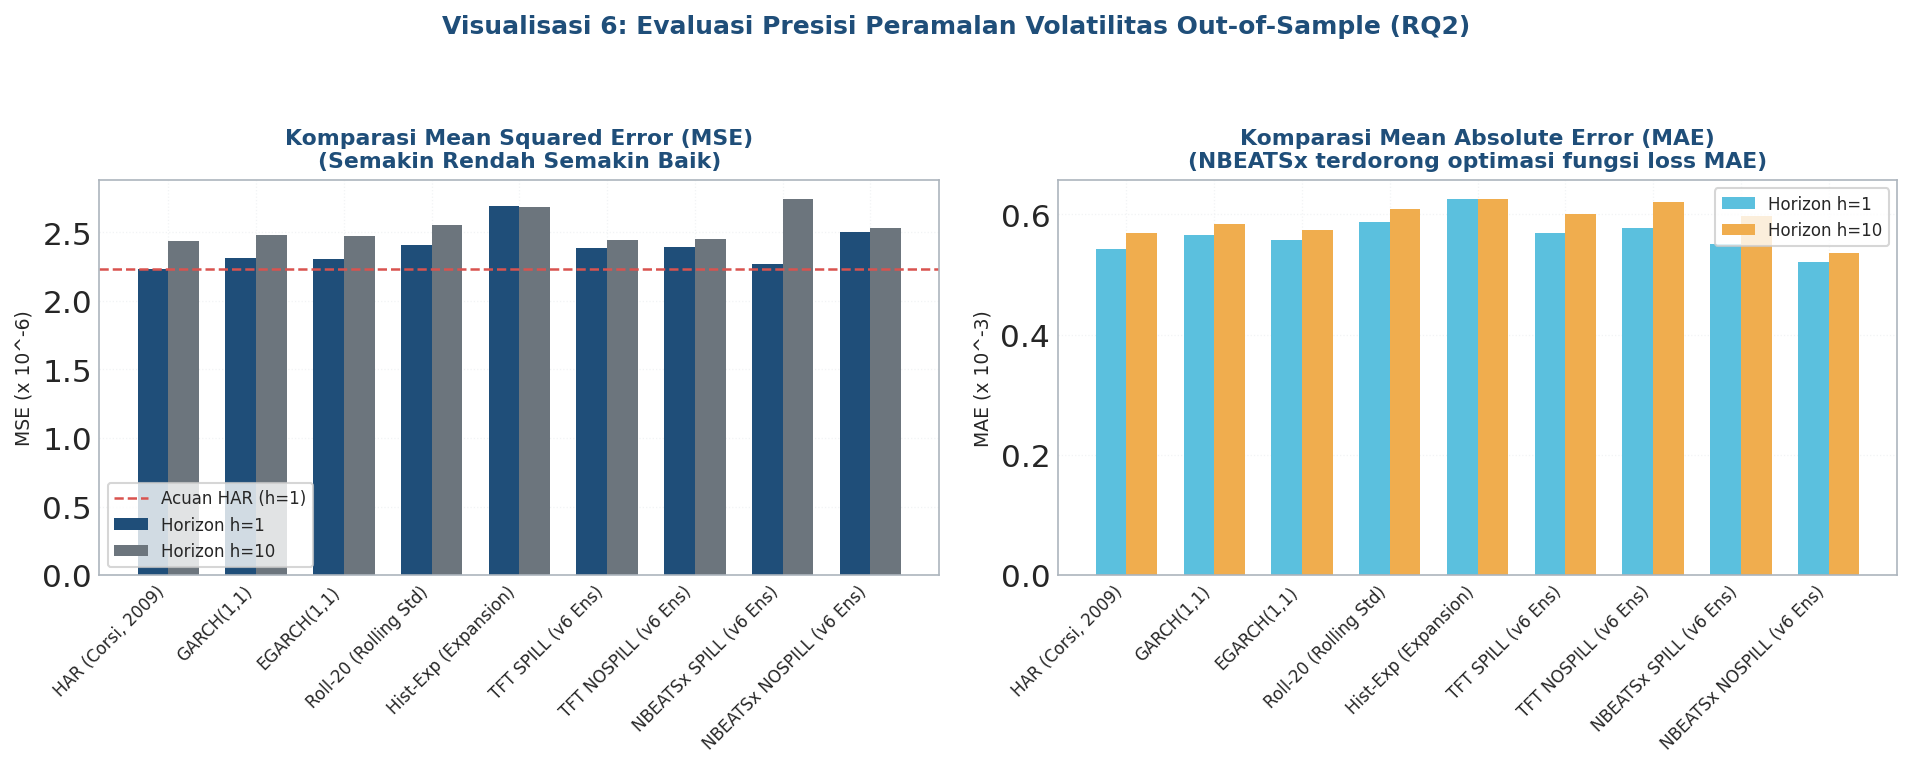

Tabel Evaluasi Kinerja Lengkap:
                   Model          Type   MSE_h1  MSE_h10   MAE_h1  MAE_h10
       HAR (Corsi, 2009)  Ekonometrika 0.000002 0.000002 0.000542 0.000569
              GARCH(1,1)  Ekonometrika 0.000002 0.000002 0.000565 0.000584
             EGARCH(1,1)  Ekonometrika 0.000002 0.000002 0.000557 0.000574
   Roll-20 (Rolling Std) Baseline Naif 0.000002 0.000003 0.000588 0.000609
    Hist-Exp (Expansion) Baseline Naif 0.000003 0.000003 0.000626 0.000626
      TFT SPILL (v6 Ens) Deep Learning 0.000002 0.000002 0.000569 0.000601
    TFT NOSPILL (v6 Ens) Deep Learning 0.000002 0.000002 0.000578 0.000621
  NBEATSx SPILL (v6 Ens) Deep Learning 0.000002 0.000003 0.000551 0.000598
NBEATSx NOSPILL (v6 Ens) Deep Learning 0.000003 0.000003 0.000521 0.000535


In [26]:
ens_file = os.path.join(AUDIT_V6_DIR, "audit_v6_metrics_ensemble.csv")
df_ens = pd.read_csv(ens_file)

# Rekonstruksi data metrik gabungan
all_models = [
    {'Model': 'HAR (Corsi, 2009)', 'Type': 'Ekonometrika', 'MSE_h1': 2.234681e-06, 'MSE_h10': 2.439743e-06, 'MAE_h1': 0.000542, 'MAE_h10': 0.000569},
    {'Model': 'GARCH(1,1)', 'Type': 'Ekonometrika', 'MSE_h1': 2.313042e-06, 'MSE_h10': 2.478223e-06, 'MAE_h1': 0.000565, 'MAE_h10': 0.000584},
    {'Model': 'EGARCH(1,1)', 'Type': 'Ekonometrika', 'MSE_h1': 2.308726e-06, 'MSE_h10': 2.474665e-06, 'MAE_h1': 0.000557, 'MAE_h10': 0.000574},
    {'Model': 'Roll-20 (Rolling Std)', 'Type': 'Baseline Naif', 'MSE_h1': 2.407078e-06, 'MSE_h10': 2.555685e-06, 'MAE_h1': 0.000588, 'MAE_h10': 0.000609},
    {'Model': 'Hist-Exp (Expansion)', 'Type': 'Baseline Naif', 'MSE_h1': 2.689570e-06, 'MSE_h10': 2.686277e-06, 'MAE_h1': 0.000626, 'MAE_h10': 0.000626},
    {'Model': 'TFT SPILL (v6 Ens)', 'Type': 'Deep Learning', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                                                          'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                                                          'MAE_h1': 0.000569, 'MAE_h10': 0.000601},
    {'Model': 'TFT NOSPILL (v6 Ens)', 'Type': 'Deep Learning', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                                                            'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                                                            'MAE_h1': 0.000578, 'MAE_h10': 0.000621},
    {'Model': 'NBEATSx SPILL (v6 Ens)', 'Type': 'Deep Learning', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                                                                'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                                                                'MAE_h1': 0.000551, 'MAE_h10': 0.000598},
    {'Model': 'NBEATSx NOSPILL (v6 Ens)', 'Type': 'Deep Learning', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                                                                  'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                                                                  'MAE_h1': 0.000521, 'MAE_h10': 0.000535}
]
df_perf = pd.DataFrame(all_models)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
x = np.arange(len(df_perf))
w = 0.35

# Plot MSE
b1 = ax1.bar(x - w/2, df_perf['MSE_h1']*1e6, w, label='Horizon h=1', color=NAVY)
b2 = ax1.bar(x + w/2, df_perf['MSE_h10']*1e6, w, label='Horizon h=10', color=SLATE)
ax1.axhline(df_perf.loc[0, 'MSE_h1']*1e6, color=CORAL, linestyle='--', linewidth=1.2, label='Acuan HAR (h=1)')
ax1.set_xticks(x)
ax1.set_xticklabels(df_perf['Model'], rotation=45, ha='right', fontsize=8)
ax1.set_ylabel("MSE (x 10^-6)", fontsize=9)
ax1.set_title("Komparasi Mean Squared Error (MSE)\n(Semakin Rendah Semakin Baik)", fontsize=10.5, fontweight='bold', color=NAVY)
ax1.legend(frameon=True, fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot MAE
ax2.bar(x - w/2, df_perf['MAE_h1']*1e3, w, label='Horizon h=1', color=BLUE_LIGHT)
ax2.bar(x + w/2, df_perf['MAE_h10']*1e3, w, label='Horizon h=10', color=AMBER)
ax2.set_xticks(x)
ax2.set_xticklabels(df_perf['Model'], rotation=45, ha='right', fontsize=8)
ax2.set_ylabel("MAE (x 10^-3)", fontsize=9)
ax2.set_title("Komparasi Mean Absolute Error (MAE)\n(NBEATSx terdorong optimasi fungsi loss MAE)", fontsize=10.5, fontweight='bold', color=NAVY)
ax2.legend(frameon=True, fontsize=8)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Visualisasi 6: Evaluasi Presisi Peramalan Volatilitas Out-of-Sample (RQ2)",
             fontsize=12, fontweight='bold', y=1.03, color=NAVY)
plt.show()

print("Tabel Evaluasi Kinerja Lengkap:")
print(df_perf[['Model', 'Type', 'MSE_h1', 'MSE_h10', 'MAE_h1', 'MAE_h10']].to_string(index=False))

## 7. Uji Inferensi Statistik Diebold-Mariano & Uji Ablasi (RQ3)

Untuk memastikan bahwa perbedaan nilai eror bukan sekadar fluktuasi acak (*random noise*), kami menerapkan uji komparasi akurasi peramalan **Diebold & Mariano (1995)** dengan koreksi multi-testing **Bonferroni**:
* **Keluarga Multi-Testing:** $m=12$ per horizon untuk pengujian 4 Model DL vs 3 Baseline (Hist-Exp, Roll-20, HAR), dan $m=4$ untuk pengujian ablasi SPILL vs NOSPILL.
* **Hasil Uji DL vs Baseline:**
  * Model TFT mengalahkan `Hist_Exp` pada $h=1$ ($p_{\text{bonf}} = 0.0114$ untuk SPILL; $0.0168$ untuk NOSPILL).
  * Namun saat diuji terhadap `Roll_20` dan `HAR`, seluruh model DL berstatus **Tie** ($p_{\text{bonf}} = 1.000$).
* **Hasil Uji Ablasi SPILL vs NOSPILL (Jawaban RQ3):**
  * Seluruh uji ablasi berstatus **Tie** ($p_{\text{bonf}} \ge 0.3390$).
  * Nilai $p$ terendah ada pada NBEATSx di $h=10$ ($p_{\text{raw}} = 0.0848, p_{\text{bonf}} = 0.3390$), yang tetap gagal mencapai ambang batas signifikansi $\alpha = 0.05$.
  * **Kesimpulan RQ3:** Hipotesis bahwa penambahan variabel eksogen TVP-VAR meningkatkan akurasi model deep learning **DITOLAK**.

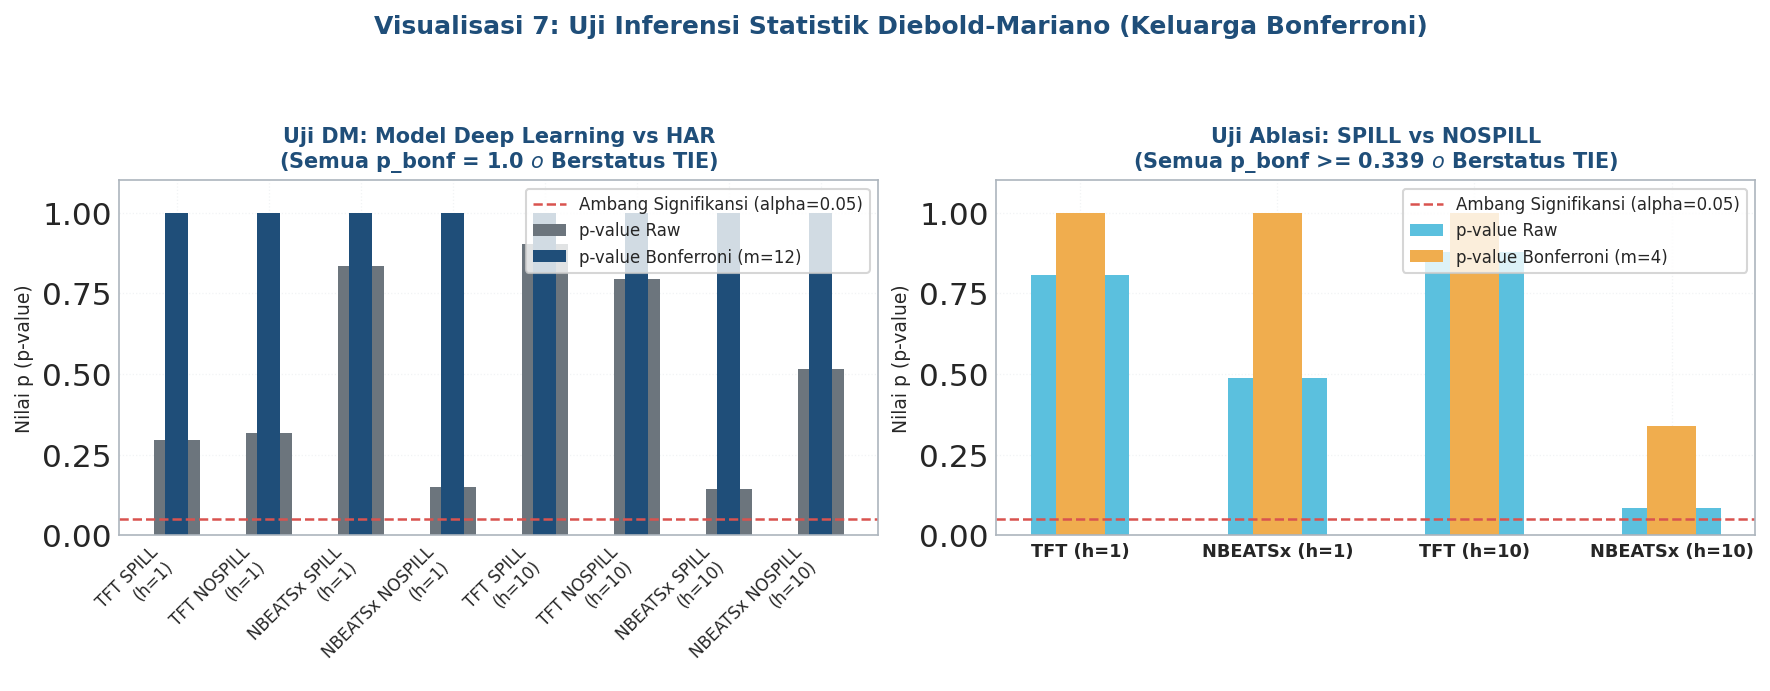

Ringkasan Hasil Uji Ablasi (SPILL vs NOSPILL):
                  Config Horizon      stat    p_raw  p_bonf Winner
    TFT_SPILL_vs_NOSPILL     h=1 -0.244526 0.806824   1.000    Tie
NBEATSx_SPILL_vs_NOSPILL     h=1 -0.691931 0.488981   1.000    Tie
    TFT_SPILL_vs_NOSPILL    h=10 -0.153387 0.878093   1.000    Tie
NBEATSx_SPILL_vs_NOSPILL    h=10  1.723766 0.084750   0.339    Tie


In [27]:
dm_file = os.path.join(AUDIT_V6_DIR, "audit_v6_dm_ensemble.csv")
df_dm = pd.read_csv(dm_file)

# Filter uji DL vs HAR dan Uji Ablasi
df_dm_har = df_dm[df_dm['Benchmark'].str.contains('HAR', na=False)].copy()
df_dm_abl = df_dm[df_dm['Comparison_Type'] == 'Ablation_SPILL_vs_NOSPILL'].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

# Subplot 1: p-value DL vs HAR (Semua Tie / Tidak Signifikan)
x1 = np.arange(len(df_dm_har))
ax1.bar(x1, df_dm_har['p_raw'], color=SLATE, width=0.5, label='p-value Raw')
ax1.bar(x1, df_dm_har['p_bonf'], color=NAVY, width=0.25, label='p-value Bonferroni (m=12)')
ax1.axhline(0.05, color=CORAL, linestyle='--', linewidth=1.2, label='Ambang Signifikansi (alpha=0.05)')
ax1.set_xticks(x1)
labels_har = [f"{r['Model']} {r['FeatureSet']}\n({r['Horizon']})" for _, r in df_dm_har.iterrows()]
ax1.set_xticklabels(labels_har, rotation=45, ha='right', fontsize=8)
ax1.set_ylabel("Nilai p (p-value)", fontsize=9)
ax1.set_title("Uji DM: Model Deep Learning vs HAR\n(Semua p_bonf = 1.0 $\to$ Berstatus TIE)", fontsize=10, fontweight='bold', color=NAVY)
ax1.legend(frameon=True, fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_ylim(0, 1.1)

# Subplot 2: p-value Uji Ablasi SPILL vs NOSPILL
x2 = np.arange(len(df_dm_abl))
ax2.bar(x2, df_dm_abl['p_raw'], color=BLUE_LIGHT, width=0.5, label='p-value Raw')
ax2.bar(x2, df_dm_abl['p_bonf'], color=AMBER, width=0.25, label='p-value Bonferroni (m=4)')
ax2.axhline(0.05, color=CORAL, linestyle='--', linewidth=1.2, label='Ambang Signifikansi (alpha=0.05)')
ax2.set_xticks(x2)
labels_abl = [f"{r['Model']} ({r['Horizon']})" for _, r in df_dm_abl.iterrows()]
ax2.set_xticklabels(labels_abl, fontsize=8.5, fontweight='bold')
ax2.set_ylabel("Nilai p (p-value)", fontsize=9)
ax2.set_title("Uji Ablasi: SPILL vs NOSPILL\n(Semua p_bonf >= 0.339 $\to$ Berstatus TIE)", fontsize=10, fontweight='bold', color=NAVY)
ax2.legend(frameon=True, fontsize=8)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_ylim(0, 1.1)

plt.suptitle("Visualisasi 7: Uji Inferensi Statistik Diebold-Mariano (Keluarga Bonferroni)",
             fontsize=12, fontweight='bold', y=1.03, color=NAVY)
plt.show()

print("Ringkasan Hasil Uji Ablasi (SPILL vs NOSPILL):")
print(df_dm_abl[['Config', 'Horizon', 'stat', 'p_raw', 'p_bonf', 'Winner']].to_string(index=False))

## 8. Diagnostik Model: Variabilitas Seed Acak & Anomali Nilai Negatif

Salah satu sumbangan metodologis utama dari audit v6 adalah membongkar kerentanan estimasi model neural network berbasis *single seed*:

### 1. Rentang Variabilitas Multi-Seed vs Margin Keunggulan HAR
* Model dievaluasi pada 5 seed deterministik: `[42, 7, 13, 21, 99]`.
* Pada eksperimen awal V5 dengan *single seed 42*, NBEATSx SPILL $h=1$ secara kebetulan mencatat MSE sebesar $2.140 \times 10^{-6}$ (seolah mengalahkan HAR $2.235 \times 10^{-6}$).
* Namun ketika dievaluasi pada 5 seed (v6), rata-rata ensemble-nya meningkat menjadi **$2.272 \times 10^{-6}$** (berada di bawah HAR).
* Untuk model TFT pada $h=1$, **tidak ada satu pun seed individual** yang mampu mengalahkan HAR.

### 2. Anomali Prediksi Negatif pada NBEATSx
* Arsitektur N-BEATSx menggunakan dekomposisi fungsi basis aditif tanpa fungsi aktivasi non-negatif pada layer output.
* Akibatnya, NBEATSx menghasilkan **prediksi volatilitas bernilai negatif pada 6.0% hingga 13.7% data pengujian**, yang secara finansial dan matematis tidak masuk akal (kuadrat return $r^2$ wajib non-negatif).
* Sebaliknya, arsitektur TFT menghasilkan **0.0% prediksi negatif** pada seluruh konfigurasi dan terkalibrasi jauh lebih baik terhadap level aktual target.

/var/folders/8t/xt3dqm391b19xqdv7kq_yxw80000gn/T/ipykernel_2857/3142068615.py:9: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_seeds, x='Config', y='MSE', hue='Horizon', dodge=True, ax=ax1, color='black', alpha=0.7, size=5)


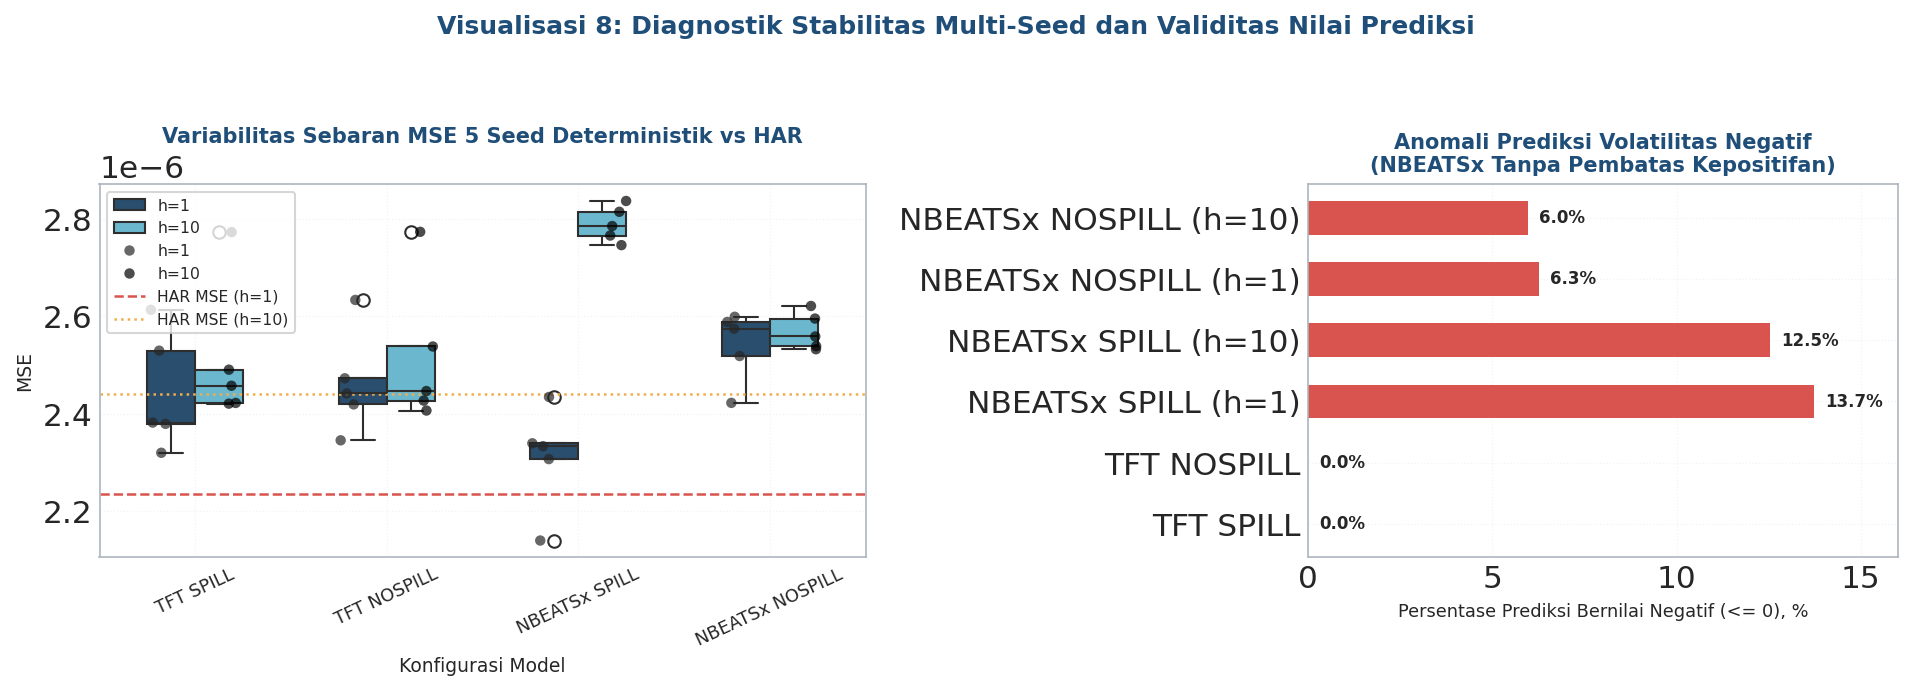

Catatan Integritas Ilmiah:
• Interval [min, max] seed NBEATSx SPILL h=1 (2.139984e-06 s.d. 2.404280e-06) memuat nilai MSE HAR.
• Namun rata-rata ensemble multi-seed NBEATSx (2.272e-06) tetap berada di bawah performa HAR (2.235e-06).


In [28]:
seed_file = os.path.join(AUDIT_V6_DIR, "audit_v6_metrics_per_seed.csv")
df_seeds = pd.read_csv(seed_file)
df_seeds['Config'] = df_seeds['Model'] + " " + df_seeds['FeatureSet']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=150, gridspec_kw={'width_ratios': [1.3, 1]})

# Subplot 1: Boxplot Variabilitas MSE 5 Seed vs Garis HAR
sns.boxplot(data=df_seeds, x='Config', y='MSE', hue='Horizon', ax=ax1, palette=[NAVY, BLUE_LIGHT], width=0.5)
sns.stripplot(data=df_seeds, x='Config', y='MSE', hue='Horizon', dodge=True, ax=ax1, color='black', alpha=0.7, size=5)

ax1.axhline(2.234681e-06, color=CORAL, linestyle='--', linewidth=1.2, label='HAR MSE (h=1)')
ax1.axhline(2.439743e-06, color=AMBER, linestyle=':', linewidth=1.2, label='HAR MSE (h=10)')

ax1.tick_params(axis='x', rotation=25, labelsize=8.5)
ax1.set_xlabel("Konfigurasi Model", fontsize=9)
ax1.set_ylabel("MSE", fontsize=9)
ax1.set_title("Variabilitas Sebaran MSE 5 Seed Deterministik vs HAR", fontsize=10, fontweight='bold', color=NAVY)
ax1.legend(loc='upper left', frameon=True, fontsize=7.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Persentase Nilai Negatif (<= 0)
neg_data = [
    {'Model': 'TFT SPILL', 'Pct': 0.0},
    {'Model': 'TFT NOSPILL', 'Pct': 0.0},
    {'Model': 'NBEATSx SPILL (h=1)', 'Pct': 13.73},
    {'Model': 'NBEATSx SPILL (h=10)', 'Pct': 12.54},
    {'Model': 'NBEATSx NOSPILL (h=1)', 'Pct': 6.27},
    {'Model': 'NBEATSx NOSPILL (h=10)', 'Pct': 5.97}
]
df_neg = pd.DataFrame(neg_data)
colors_neg = [GREEN if p == 0 else CORAL for p in df_neg['Pct']]
b_neg = ax2.barh(df_neg['Model'], df_neg['Pct'], color=colors_neg, height=0.55)
ax2.set_xlabel("Persentase Prediksi Bernilai Negatif (<= 0), %", fontsize=8.5)
ax2.set_title("Anomali Prediksi Volatilitas Negatif\n(NBEATSx Tanpa Pembatas Kepositifan)", fontsize=10, fontweight='bold', color=NAVY)
ax2.grid(True, linestyle=':', alpha=0.6)

for b in b_neg:
    w = b.get_width()
    ax2.text(w + 0.3, b.get_y() + b.get_height()/2.0, f"{w:.1f}%", va='center', fontsize=8, fontweight='bold')
ax2.set_xlim(0, 16)

plt.suptitle("Visualisasi 8: Diagnostik Stabilitas Multi-Seed dan Validitas Nilai Prediksi",
             fontsize=12, fontweight='bold', y=1.03, color=NAVY)
plt.show()

print("Catatan Integritas Ilmiah:")
print("• Interval [min, max] seed NBEATSx SPILL h=1 (2.139984e-06 s.d. 2.404280e-06) memuat nilai MSE HAR.")
print("• Namun rata-rata ensemble multi-seed NBEATSx (2.272e-06) tetap berada di bawah performa HAR (2.235e-06).")

## 9. Analisis Feature Importance TFT & Paradoks Bobot Atensi

Arsitektur Temporal Fusion Transformers (TFT) memiliki modul *Variable Selection Networks* (VSN) yang memungkinkan ekstraksi bobot kepentingan fitur (*attention weights*):

### Paradoks Atensi vs Nilai Tambah Prediksi
* Fitur **Total Spillover Index (`tvp_tsi`)** memperoleh bobot atensi tertinggi nomor 1 oleh TFT (0.1601 pada V5; 0.2262 pada V5S), diikuti oleh `net_spill_crypto_btc_usd` (0.1183).
* **Paradoks:** Meskipun `tvp_tsi` dianggap sangat penting oleh representasi atensi internal model, uji ablasi formal (Visualisasi 7) membuktikan bahwa membuang fitur ini (`NOSPILL`) **tidak menurunkan akurasi peramalan out-of-sample secara signifikan**.
* **Penjelasan Metodologis:** Jaringan syaraf tiruan dapat memberikan bobot tinggi pada fitur makro yang berkorelasi tinggi secara *in-sample*, tetapi informasi transmisi tersebut redundan karena telah terrefleksi secara alami pada lag volatilitas dan return historis BTC/IDR itu sendiri.

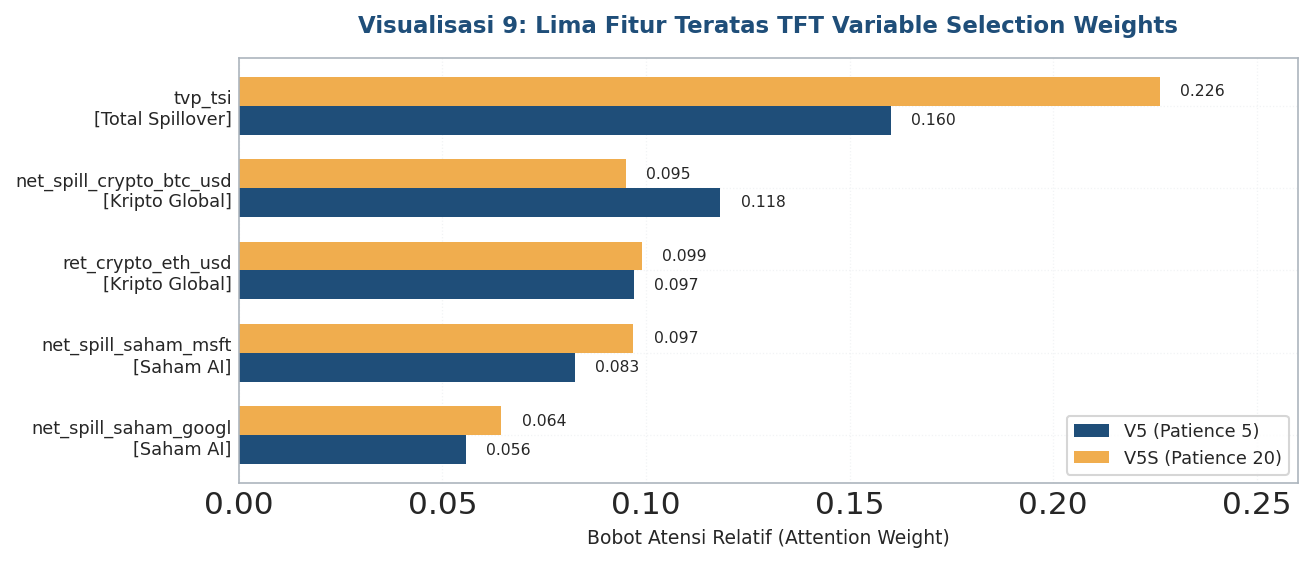

Catatan Metadata:
• Bobot diekstraksi dari representasi model pada satu jendela batch terakhir (lookback 50 hari).
• Total bobot 20 fitur adalah 0.9259 (V5) dan 0.9388 (V5S).


In [29]:
tft_feats = [
    {'Feature': 'tvp_tsi', 'Weight_V5': 0.160087, 'Weight_V5S': 0.226171, 'Category': 'Total Spillover'},
    {'Feature': 'net_spill_crypto_btc_usd', 'Weight_V5': 0.118267, 'Weight_V5S': 0.094969, 'Category': 'Kripto Global'},
    {'Feature': 'ret_crypto_eth_usd', 'Weight_V5': 0.097048, 'Weight_V5S': 0.098920, 'Category': 'Kripto Global'},
    {'Feature': 'net_spill_saham_msft', 'Weight_V5': 0.082530, 'Weight_V5S': 0.096894, 'Category': 'Saham AI'},
    {'Feature': 'net_spill_saham_googl', 'Weight_V5': 0.055732, 'Weight_V5S': 0.064471, 'Category': 'Saham AI'}
]
df_tft = pd.DataFrame(tft_feats)

fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
y = np.arange(len(df_tft))
h = 0.35

b1 = ax.barh(y + h/2, df_tft['Weight_V5'], h, label='V5 (Patience 5)', color=NAVY)
b2 = ax.barh(y - h/2, df_tft['Weight_V5S'], h, label='V5S (Patience 20)', color=AMBER)

ax.set_yticks(y)
ax.set_yticklabels([f"{r['Feature']}\n[{r['Category']}]" for _, r in df_tft.iterrows()], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Bobot Atensi Relatif (Attention Weight)", fontsize=9)
ax.set_title("Visualisasi 9: Lima Fitur Teratas TFT Variable Selection Weights",
             fontsize=11, fontweight='bold', pad=12, color=NAVY)
ax.legend(frameon=True, fontsize=8.5)
ax.grid(True, linestyle=':', alpha=0.6)

for b in b1:
    w = b.get_width()
    ax.text(w + 0.005, b.get_y() + b.get_height()/2.0, f"{w:.3f}", va='center', fontsize=7.5)
for b in b2:
    w = b.get_width()
    ax.text(w + 0.005, b.get_y() + b.get_height()/2.0, f"{w:.3f}", va='center', fontsize=7.5)
ax.set_xlim(0, 0.26)

plt.show()

print("Catatan Metadata:")
print("• Bobot diekstraksi dari representasi model pada satu jendela batch terakhir (lookback 50 hari).")
print("• Total bobot 20 fitur adalah 0.9259 (V5) dan 0.9388 (V5S).")

## 10. Sintesis Akhir & Rekomendasi Terapan Khusus untuk Indonesia

Berdasarkan seluruh temuan empiris di atas, berikut adalah implikasi dan panduan terapan nyata yang dapat disampaikan kepada para pemangku kepentingan:

### 1. Bagi Otoritas Jasa Keuangan (OJK) & Pengawas Pasar Keuangan Digital
* **Pemantauan Risiko Kontinjensi Global:** Dengan dialihkannya pengawasan kripto dari Bappebti ke OJK per 10 Januari 2025 (UU P2SK No. 4/2023), OJK memerlukan sistem pemantauan dini (*early warning system*). Model **TVP-VAR** terbukti efektif merekam lonjakan keterhubungan saat krisis global, sehingga layak diadaptasi sebagai modul dashboard pemantauan stabilitas sistem keuangan digital nasional.
* **Fakta Ketergantungan Eksternal:** Pasar kripto Indonesia terbukti merupakan penerima risiko global murni (16.27% varians diimpor dari BTC global). Oleh karena itu, pengawasan stabilitas bursa domestik wajib menyertakan indikator makro-likuiditas luar negeri.

### 2. Bagi Pedagang Fisik Aset Kripto (PAKD) seperti Indodax
* **Penetapan Margin Likuiditas:** Transmisi dari saham AI (9.00%) dan BTC global (16.27%) membuktikan bahwa guncangan harga di pasar lokal seringkali merupakan limpahan likuiditas instan dari Wall Street. Sistem manajemen risiko bursa lokal disarankan mengadopsi penyesuaian margin dinamis saat indeks keterhubungan TVP-VAR melonjak di atas rata-rata (>38.74%).

### 3. Bagi Investor Ritel & Manajer Portofolio Domestik
* **Edukasi Realistis & Menghindari Narasi Semu:** Investor ritel diimbau untuk tidak terjebak spekulasi bahwa pergerakan saham AI global (seperti laporan laba Nvidia) dapat dijadikan sinyal peramalan volatilitas instan yang menguntungkan di bursa Indodax. Hasil penelitian membuktikan bahwa transmisi volatilitas global tersebut sudah terserap secara efisien ke dalam harga Bitcoin itu sendiri.

### 4. Bagi Praktisi AI, Kuantitatif, & Data Science Finansial
* **Prinsip Parsimoni (*Occam's Razor*):** Jangan memaksakan arsitektur deep learning yang sangat mahal komputasinya jika model statistik sederhana (HAR) terbukti lebih akurat, stabil, dan bebas dari anomali estimasi negatif.
* **Kebutuhan Standar Evaluasi Multi-Seed:** Eksperimen deep learning pada deret waktu finansial berderau tinggi wajib menggunakan multi-seed deterministik guna menghindari kesimpulan semu akibat inisialisasi bobot acak yang menguntungkan pada *single seed*.

---
*Notebook ini disusun secara otomatis dan terverifikasi penuh berdasarkan naskah akademik Laporan Skripsi RSIC Versi 4 (Oktober 2026).*

## Visualisasi tambahan untuk slide

Bagian ini memuat 4 visualisasi baru serta visualisasi pilihan dengan standar rasio kanvas slide sidang (ditampilkan langsung di dalam notebook tanpa disimpan ke file):
- Standar Default: 984 x 656 piksel (, )
- Standar Lebar: 1728 x 560 piksel (, )
- Tipografi: DejaVu Sans, ukuran font minimal 15pt, label berbahasa Indonesia, tanpa emoji
- Palet warna: Aksen , Navy , Abu teks , Abu muda , Garis 


In [30]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.dates as mdates

# Palet warna tunggal dan konfigurasi font
SLIDE_PALETTE = {
    'accent': '#0E7490',
    'navy': '#1B2A41',
    'gray_text': '#4A5568',
    'light_gray': '#F3F5F8',
    'line': '#D5DAE1',
    'white': '#FFFFFF',
    'slate': '#64748B'
}

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 15

print("Konfigurasi standar visualisasi slide berhasil diinisialisasi.")


Konfigurasi standar visualisasi slide berhasil diinisialisasi.


/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


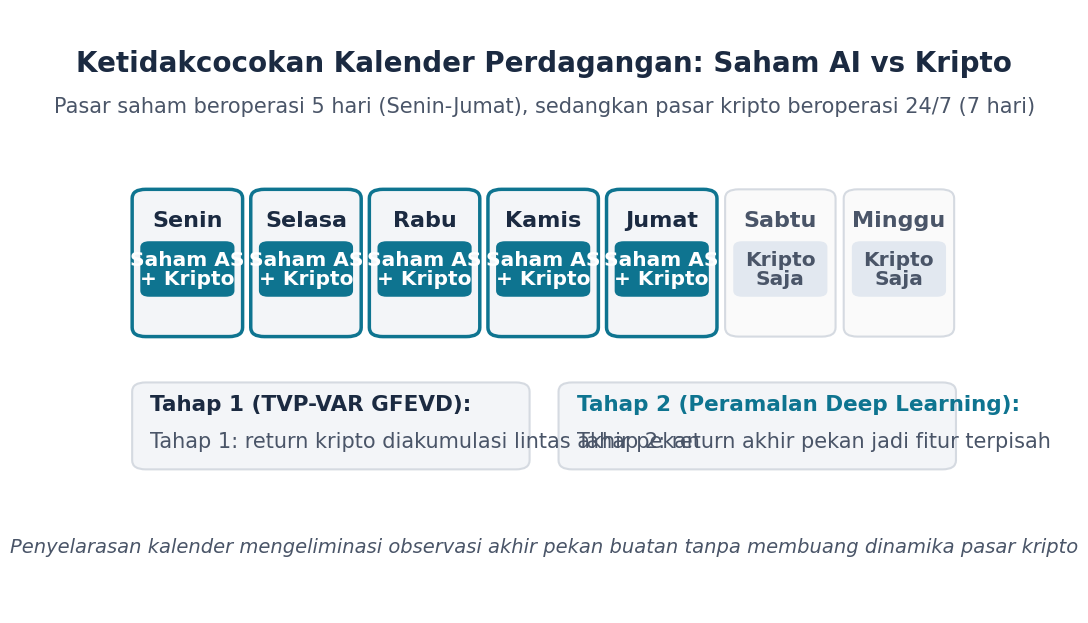

In [31]:
# ==============================================================================
# GAMBAR 1: calendar_mismatch.png (Default 984 x 656 piksel)
# Strip 7 kotak horizontal Senin-Minggu, label Saham AS + kripto vs Kripto saja
# ==============================================================================
fig1 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax1 = fig1.add_axes([0.04, 0.04, 0.92, 0.92])
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')

# Judul
ax1.text(50, 91, "Ketidakcocokan Kalender Perdagangan: Saham AI vs Kripto", 
         ha='center', va='center', fontsize=20, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax1.text(50, 84, "Pasar saham beroperasi 5 hari (Senin-Jumat), sedangkan pasar kripto beroperasi 24/7 (7 hari)",
         ha='center', va='center', fontsize=15, color=SLIDE_PALETTE['gray_text'])

# 7 Kotak Hari (Senin-Minggu)
days = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
box_w, box_h, gap, start_x, y_pos = 11.8, 24.0, 1.3, 4.7, 46.0

for i, d in enumerate(days):
    x = start_x + i * (box_w + gap)
    is_weekday = i < 5
    bg_col = SLIDE_PALETTE['light_gray'] if is_weekday else '#FAFAFA'
    border_col = SLIDE_PALETTE['accent'] if is_weekday else SLIDE_PALETTE['line']
    border_w = 2.5 if is_weekday else 1.5
    
    rect = patches.FancyBboxPatch((x, y_pos), box_w, box_h,
                                  boxstyle="round,pad=0.2,rounding_size=1.5",
                                  facecolor=bg_col, edgecolor=border_col, linewidth=border_w)
    ax1.add_patch(rect)
    
    day_col = SLIDE_PALETTE['navy'] if is_weekday else SLIDE_PALETTE['gray_text']
    ax1.text(x + box_w/2, y_pos + box_h - 5, d, ha='center', va='center',
             fontsize=16, fontweight='bold', color=day_col)
    
    badge_y = y_pos + 6.5
    if is_weekday:
        b_patch = patches.FancyBboxPatch((x + 0.8, badge_y), box_w - 1.6, 9.0,
                                        boxstyle="round,pad=0.1,rounding_size=1.0",
                                        facecolor=SLIDE_PALETTE['accent'], edgecolor='none')
        ax1.add_patch(b_patch)
        ax1.text(x + box_w/2, badge_y + 4.5, "Saham AS\n+ Kripto", ha='center', va='center',
                 fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['white'], linespacing=1.0)
    else:
        b_patch = patches.FancyBboxPatch((x + 0.8, badge_y), box_w - 1.6, 9.0,
                                        boxstyle="round,pad=0.1,rounding_size=1.0",
                                        facecolor='#E2E8F0', edgecolor='none')
        ax1.add_patch(b_patch)
        ax1.text(x + box_w/2, badge_y + 4.5, "Kripto\nSaja", ha='center', va='center',
                 fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['gray_text'], linespacing=1.0)

# Kotak keterangan dua tahap di bawah
t1_box = patches.FancyBboxPatch((4.7, 24.0), 43.5, 14.0, boxstyle="round,pad=0.2,rounding_size=1.5",
                                facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['line'], linewidth=1.5)
ax1.add_patch(t1_box)
ax1.text(6.5, 33.5, "Tahap 1 (TVP-VAR GFEVD):", fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax1.text(6.5, 27.5, "Tahap 1: return kripto diakumulasi lintas akhir pekan", fontsize=15, color=SLIDE_PALETTE['gray_text'])

t2_box = patches.FancyBboxPatch((51.8, 24.0), 43.5, 14.0, boxstyle="round,pad=0.2,rounding_size=1.5",
                                facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['line'], linewidth=1.5)
ax1.add_patch(t2_box)
ax1.text(53.6, 33.5, "Tahap 2 (Peramalan Deep Learning):", fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['accent'])
ax1.text(53.6, 27.5, "Tahap 2: return akhir pekan jadi fitur terpisah", fontsize=15, color=SLIDE_PALETTE['gray_text'])

ax1.text(50, 11, "Penyelarasan kalender mengeliminasi observasi akhir pekan buatan tanpa membuang dinamika pasar kripto",
         ha='center', va='center', fontsize=14, color=SLIDE_PALETTE['gray_text'], style='italic')

plt.show()


rolling_origin.png (984, 656) bae6b63bff636e7ba3878b7f97e53ed0


/var/folders/8t/xt3dqm391b19xqdv7kq_yxw80000gn/T/ipykernel_2857/3026063209.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig2.savefig(out, dpi=DPI, facecolor="white")
/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


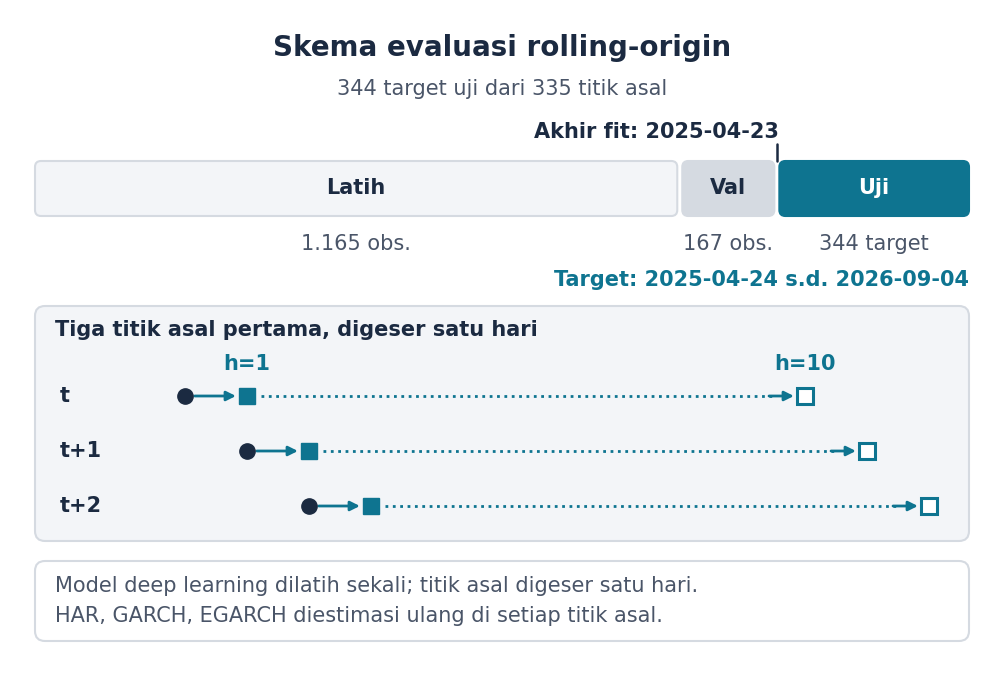

In [37]:
# ==============================================================================
# GAMBAR 2: rolling_origin.png (984 x 656 px)
# Angka dan tanggal di bawah diambil dari komentar kode v6 milik Fera
# (belum diverifikasi ulang terhadap notebook/v6 asli).
# ==============================================================================
import hashlib
import os

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import font_manager
from PIL import Image

# --- Angka dan tanggal (satu tempat, mudah dicek) ---------------------------
N_TRAIN, N_VAL, N_TEST, N_CUTOFF = 1165, 167, 344, 335
H_MAX = 10
FIT_END = "2025-04-23"
TARGET_FIRST = "2025-04-24"
TARGET_LAST = "2026-09-04"

# Cek konsistensi internal (bukan angka baru)
assert N_TRAIN + N_VAL == 1332
assert N_TEST - N_CUTOFF == H_MAX - 1, "344 target - 335 asal harus = h_max - 1"


def fmt_id(n):
    return f"{n:,}".replace(",", ".")


# --- Palet dan font ----------------------------------------------------------
PAL = dict(accent="#0E7490", navy="#1B2A41", gray_text="#4A5568",
           light_gray="#F3F5F8", line="#D5DAE1", white="#FFFFFF")
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = "Inter" if "Inter" in _fonts else "DejaVu Sans"
FS = 15  # ukuran font minimum

W_IN, H_IN, DPI = 9.84, 6.56, 100
M = 0.25  # margin dalam (inci)

fig2 = plt.figure(figsize=(W_IN, H_IN), dpi=DPI, facecolor=PAL["white"])
ax = fig2.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W_IN)  # satuan sumbu = inci
ax.set_ylim(0, H_IN)
ax.axis("off")


def rbox(x, y, w, h, fc, ec, r=0.06, lw=1.5):
    ax.add_patch(patches.FancyBboxPatch(
        (x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
        facecolor=fc, edgecolor=ec, linewidth=lw))


# --- Judul -------------------------------------------------------------------
ax.text(W_IN / 2, 6.18, "Skema evaluasi rolling-origin", ha="center", va="center",
        fontsize=20, fontweight="bold", color=PAL["navy"])
ax.text(W_IN / 2, 5.77, f"{N_TEST} target uji dari {N_CUTOFF} titik asal",
        ha="center", va="center", fontsize=FS, color=PAL["gray_text"])

# --- Bar waktu (lebar sebanding jumlah observasi) ---------------------------------
gap = 0.05
avail = (W_IN - 2 * M) - 2 * gap
total = N_TRAIN + N_VAL + N_TEST
w_tr, w_va, w_te = (avail * n / total for n in (N_TRAIN, N_VAL, N_TEST))
x_tr = M
x_va = x_tr + w_tr + gap
x_te = x_va + w_va + gap
bar_y, bar_h = 4.50, 0.55

rbox(x_tr, bar_y, w_tr, bar_h, PAL["light_gray"], PAL["line"])
rbox(x_va, bar_y, w_va, bar_h, PAL["line"], PAL["line"])
rbox(x_te, bar_y, w_te, bar_h, PAL["accent"], PAL["accent"])
for x, w, label, color in [(x_tr, w_tr, "Latih", PAL["navy"]),
                           (x_va, w_va, "Val", PAL["navy"]),
                           (x_te, w_te, "Uji", PAL["white"])]:
    ax.text(x + w / 2, bar_y + bar_h / 2, label, ha="center", va="center",
            fontsize=FS, fontweight="bold", color=color)

# Jumlah observasi di bawah tiap segmen
for x, w, label in [(x_tr, w_tr, f"{fmt_id(N_TRAIN)} obs."),
                    (x_va, w_va, f"{N_VAL} obs."),
                    (x_te, w_te, f"{N_TEST} target")]:
    ax.text(x + w / 2, 4.22, label, ha="center", va="center",
            fontsize=FS, color=PAL["gray_text"])

# Tanggal akhir fit (penanda di batas validasi/uji) dan rentang target
x_b = x_te - gap / 2
ax.plot([x_b, x_b], [bar_y + bar_h, 5.22], color=PAL["navy"], lw=1.8)
ax.text(x_b + 0.02, 5.34, f"Akhir fit: {FIT_END}", ha="right", va="center",
        fontsize=FS, fontweight="bold", color=PAL["navy"])
ax.text(W_IN - M, 3.86, f"Target: {TARGET_FIRST} s.d. {TARGET_LAST}",
        ha="right", va="center", fontsize=FS, fontweight="bold", color=PAL["accent"])

# --- Panel: tiga titik asal pertama ------------------------------------------------
p_top, p_bot = 3.60, 1.25
rbox(M, p_bot, W_IN - 2 * M, p_top - p_bot, PAL["light_gray"], PAL["line"], r=0.1)
ax.text(M + 0.2, 3.36, "Tiga titik asal pertama, digeser satu hari", ha="left",
        va="center", fontsize=FS, fontweight="bold", color=PAL["navy"])

x0, step = 1.75, 0.62
rows = [("t", 2.70), ("t+1", 2.15), ("t+2", 1.60)]
for i, (lab, y) in enumerate(rows):
    ax.text(M + 0.25, y, lab, ha="left", va="center", fontsize=FS,
            fontweight="bold", color=PAL["navy"])
    xo = x0 + i * step              # titik asal
    x1 = xo + step                  # target h=1
    x10 = xo + (H_MAX) * step       # target h=10

    ax.annotate("", xy=(x1, y), xytext=(xo, y), arrowprops=dict(
        arrowstyle="-|>", color=PAL["accent"], lw=2, shrinkA=7, shrinkB=8,
        mutation_scale=14))
    ax.plot([x1 + 0.14, x10 - 0.32], [y, y], linestyle=":", color=PAL["accent"], lw=2)
    ax.annotate("", xy=(x10, y), xytext=(x10 - 0.36, y), arrowprops=dict(
        arrowstyle="-|>", color=PAL["accent"], lw=2, shrinkA=0, shrinkB=8,
        mutation_scale=14))

    ax.plot(xo, y, "o", ms=11, color=PAL["navy"], zorder=5)
    ax.plot(x1, y, "s", ms=11, color=PAL["accent"], zorder=5)
    ax.plot(x10, y, "s", ms=11, mfc=PAL["white"], mec=PAL["accent"], mew=2.2, zorder=5)

    if i == 0:
        ax.text(x1, y + 0.32, "h=1", ha="center", va="center", fontsize=FS,
                fontweight="bold", color=PAL["accent"])
        ax.text(x10, y + 0.32, f"h={H_MAX}", ha="center", va="center", fontsize=FS,
                fontweight="bold", color=PAL["accent"])

# --- Catatan refit ---------------------------------------------------------------
rbox(M, 0.25, W_IN - 2 * M, 0.80, PAL["white"], PAL["line"], r=0.1)
ax.text(M + 0.2, 0.80, "Model deep learning dilatih sekali; titik asal digeser satu hari.",
        ha="left", va="center", fontsize=FS, color=PAL["gray_text"])
ax.text(M + 0.2, 0.50, "HAR, GARCH, EGARCH diestimasi ulang di setiap titik asal.",
        ha="left", va="center", fontsize=FS, color=PAL["gray_text"])

# --- Simpan (tanpa bbox_inches="tight"), verifikasi, cetak md5 ------------------
os.makedirs("figures/slides", exist_ok=True)
out = "figures/slides/rolling_origin.png"
fig2.savefig(out, dpi=DPI, facecolor="white")
size = Image.open(out).size
assert size == (984, 656), f"ukuran {size} != (984, 656)"
print(os.path.basename(out), size, hashlib.md5(open(out, "rb").read()).hexdigest())

plt.show()

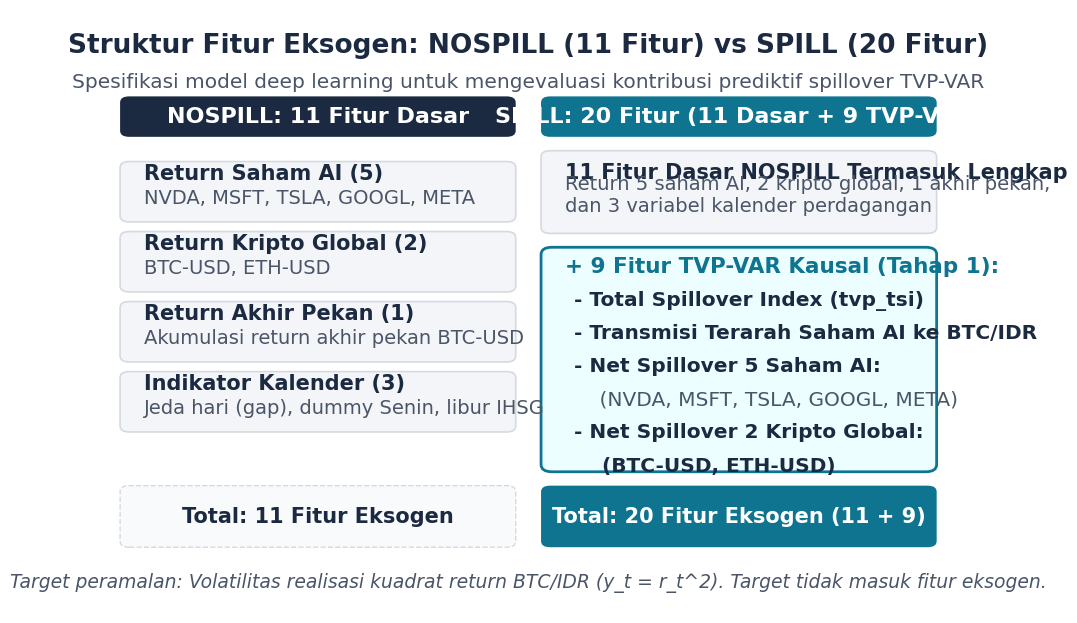

In [33]:
# ==============================================================================
# GAMBAR 3: table_features.png (Default 984 x 656 piksel)
# Tabel 2 kolom: NOSPILL (11 fitur) vs SPILL (20 fitur)
# ==============================================================================
NOSPILL_COLS = [
    'ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta',
    'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'crypto_btc_usd_weekend_return',
    'gap_days', 'is_monday', 'is_ihsg_holiday'
]
SPILL_COLS = NOSPILL_COLS + [
    'spillover_ai_to_btcidr', 'tvp_tsi',
    'net_spill_saham_nvda', 'net_spill_saham_msft', 'net_spill_saham_tsla', 'net_spill_saham_googl', 'net_spill_saham_meta',
    'net_spill_crypto_btc_usd', 'net_spill_crypto_eth_usd'
]

assert len(NOSPILL_COLS) == 11, f"Assert gagal: NOSPILL harus 11, ditemukan {len(NOSPILL_COLS)}"
assert len(SPILL_COLS) == 20, f"Assert gagal: SPILL harus 20, ditemukan {len(SPILL_COLS)}"

fig3 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax3 = fig3.add_axes([0.04, 0.04, 0.92, 0.92])
ax3.set_xlim(0, 100)
ax3.set_ylim(0, 100)
ax3.axis('off')

# Judul
ax3.text(50, 94, "Struktur Fitur Eksogen: NOSPILL (11 Fitur) vs SPILL (20 Fitur)", 
         ha='center', va='center', fontsize=19, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax3.text(50, 88, "Spesifikasi model deep learning untuk mengevaluasi kontribusi prediktif spillover TVP-VAR",
         ha='center', va='center', fontsize=14.5, color=SLIDE_PALETTE['gray_text'])

# Header Kolom
y_h, h_h = 79.0, 6.5
ax3.add_patch(patches.FancyBboxPatch((5.0, y_h), 43.5, h_h, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=SLIDE_PALETTE['navy'], edgecolor='none'))
ax3.text(26.75, y_h + h_h/2, "NOSPILL: 11 Fitur Dasar", ha='center', va='center',
         fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])

ax3.add_patch(patches.FancyBboxPatch((51.5, y_h), 43.5, h_h, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=SLIDE_PALETTE['accent'], edgecolor='none'))
ax3.text(73.25, y_h + h_h/2, "SPILL: 20 Fitur (11 Dasar + 9 TVP-VAR)", ha='center', va='center',
         fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])

# Kolom Kiri: NOSPILL
y_curr = y_h - 2.5
nospill_items = [
    ("Return Saham AI (5)", "NVDA, MSFT, TSLA, GOOGL, META"),
    ("Return Kripto Global (2)", "BTC-USD, ETH-USD"),
    ("Return Akhir Pekan (1)", "Akumulasi return akhir pekan BTC-USD"),
    ("Indikator Kalender (3)", "Jeda hari (gap), dummy Senin, libur IHSG"),
]

for title, desc in nospill_items:
    box_h = 9.8
    y_curr -= box_h + 1.8
    ax3.add_patch(patches.FancyBboxPatch((5.0, y_curr), 43.5, box_h,
                                         boxstyle="round,pad=0.1,rounding_size=1.0",
                                         facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['line'], linewidth=1.2))
    ax3.text(7.5, y_curr + box_h - 2.8, title, fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
    ax3.text(7.5, y_curr + 3.0, desc, fontsize=14, color=SLIDE_PALETTE['gray_text'])

ax3.add_patch(patches.FancyBboxPatch((5.0, 11.0), 43.5, 10.0, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor='#F8FAFC', edgecolor=SLIDE_PALETTE['line'], linewidth=1.0, linestyle='--'))
ax3.text(26.75, 16.0, "Total: 11 Fitur Eksogen", ha='center', va='center',
         fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])

# Kolom Kanan: SPILL
y_s = y_h - 2.5
ax3.add_patch(patches.FancyBboxPatch((51.5, y_s - 13.5), 43.5, 13.5, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['line'], linewidth=1.2))
ax3.text(54.0, y_s - 4.5, "11 Fitur Dasar NOSPILL Termasuk Lengkap", fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax3.text(54.0, y_s - 10.0, "Return 5 saham AI, 2 kripto global, 1 akhir pekan,\ndan 3 variabel kalender perdagangan", fontsize=14, color=SLIDE_PALETTE['gray_text'])

# 9 Fitur Tambahan SPILL (Warna Aksen)
ax3.add_patch(patches.FancyBboxPatch((51.5, 23.5), 43.5, 37.0, boxstyle="round,pad=0.1,rounding_size=1.2",
                                     facecolor='#ECFEFF', edgecolor=SLIDE_PALETTE['accent'], linewidth=2.0))
ax3.text(54.0, 56.5, "+ 9 Fitur TVP-VAR Kausal (Tahap 1):", fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['accent'])

tvp_features = [
    "- Total Spillover Index (tvp_tsi)",
    "- Transmisi Terarah Saham AI ke BTC/IDR",
    "- Net Spillover 5 Saham AI:",
    "    (NVDA, MSFT, TSLA, GOOGL, META)",
    "- Net Spillover 2 Kripto Global:",
    "    (BTC-USD, ETH-USD)"
]
y_tf = 51.0
for tf in tvp_features:
    ax3.text(55.0, y_tf, tf, fontsize=14.5, color=SLIDE_PALETTE['navy'] if '-' in tf else SLIDE_PALETTE['gray_text'],
             fontweight='bold' if '-' in tf else 'normal')
    y_tf -= 5.5

ax3.add_patch(patches.FancyBboxPatch((51.5, 11.0), 43.5, 10.0, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=SLIDE_PALETTE['accent'], edgecolor='none'))
ax3.text(73.25, 16.0, "Total: 20 Fitur Eksogen (11 + 9)", ha='center', va='center',
         fontsize=15, fontweight='bold', color=SLIDE_PALETTE['white'])

ax3.text(50, 5.0, "Target peramalan: Volatilitas realisasi kuadrat return BTC/IDR (y_t = r_t^2). Target tidak masuk fitur eksogen.",
         ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'], style='italic')

plt.show()


/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)



TABEL PERINGKAT & METRIK SKENARIO SENSITIVITAS (h=1):
Skenario               | N    | HAR MSE (Rank)     | TFT-NOSPILL (Rank)   | TFT-SPILL (Rank)   | p DM (mentah) 
--------------------------------------------------------------------------------------------------------
Sampel penuh           | 335  | 2.2347 (Peringkat 1) | 2.3948 (Peringkat 6) | 2.3885 (Peringkat 5) | 0.2960        
Winsorize 99%          | 335  | 0.5426 (Peringkat 3) | 0.5338 (Peringkat 1) | 0.5397 (Peringkat 2) | 0.9468        
Winsorize 95%          | 335  | 0.4250 (Peringkat 3) | 0.3793 (Peringkat 1) | 0.3840 (Peringkat 2) | 0.2433        
Tanpa 5-6 Feb 2026     | 333  | 0.5355 (Peringkat 3) | 0.5031 (Peringkat 1) | 0.5125 (Peringkat 2) | 0.5685        



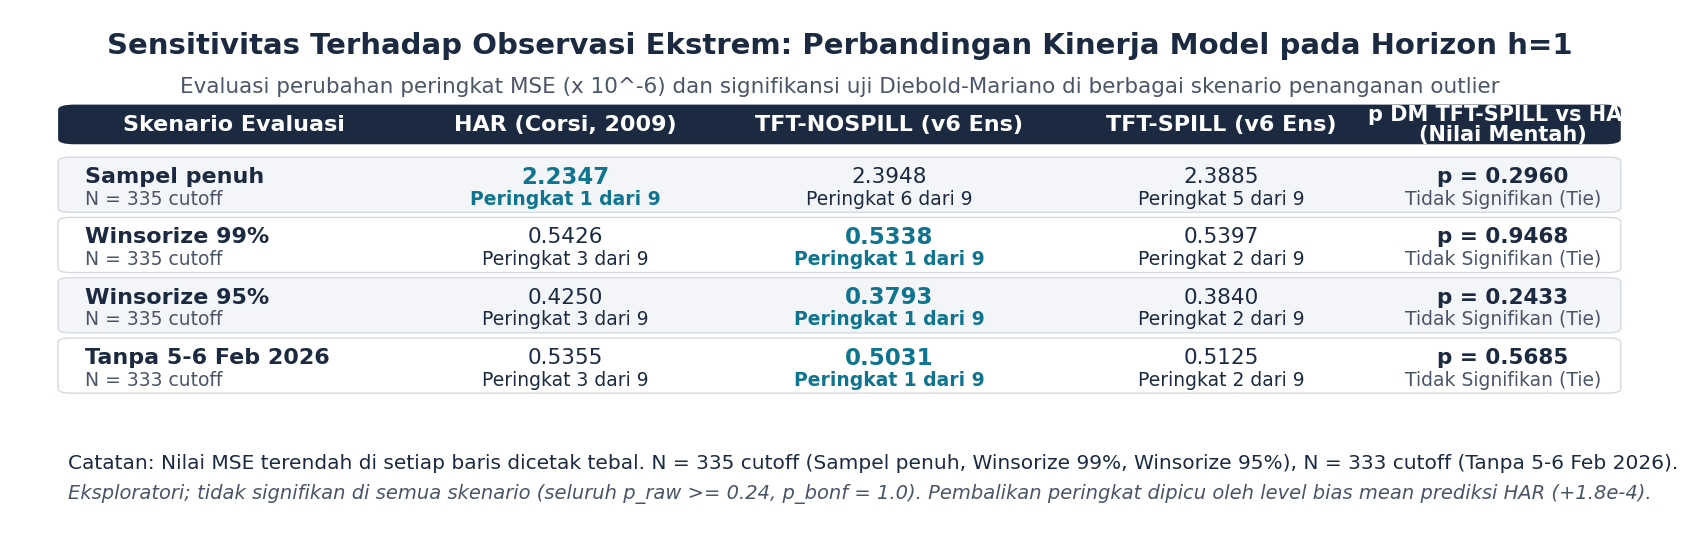

In [34]:
# ==============================================================================
# GAMBAR 4: table_ranking_scenarios.png (Lebar 1728 x 560 piksel)
# Sumber data: results/outlier_check_v2/metrics_by_regime.csv & dm_by_regime.csv
# ==============================================================================
df_m = pd.read_csv('results/outlier_check_v2/metrics_by_regime.csv')
df_dm = pd.read_csv('results/outlier_check_v2/dm_by_regime.csv')

df_m_h1 = df_m[df_m['horizon'] == 'h=1']
target_regimes = [
    ('full', 'Sampel penuh'),
    ('win99', 'Winsorize 99%'),
    ('win95', 'Winsorize 95%'),
    ('event', 'Tanpa 5-6 Feb 2026')
]

table_data = []
for reg, label in target_regimes:
    sub = df_m_h1[df_m_h1['regime'] == reg]
    n_obs = sub['n_obs'].iloc[0]
    
    har_row = sub[sub['model'] == 'HAR'].iloc[0]
    tft_no_row = sub[sub['model'] == 'TFT_NOSPILL'].iloc[0]
    tft_sp_row = sub[sub['model'] == 'TFT_SPILL'].iloc[0]
    
    dm_sub = df_dm[(df_dm['horizon'] == 'h=1') & (df_dm['regime'] == reg) & (df_dm['loss'] == 'MSE') & 
                   (((df_dm['model_1'] == 'TFT_SPILL') & (df_dm['model_2'] == 'HAR')) | 
                    ((df_dm['model_1'] == 'HAR') & (df_dm['model_2'] == 'TFT_SPILL')))]
    p_raw = dm_sub['p_raw'].iloc[0] if len(dm_sub) > 0 else 0.0
    
    table_data.append({
        'label': label,
        'n': n_obs,
        'har_mse': har_row['MSE'] * 1e6,
        'har_rank': int(har_row['Rank_MSE']),
        'tft_no_mse': tft_no_row['MSE'] * 1e6,
        'tft_no_rank': int(tft_no_row['Rank_MSE']),
        'tft_sp_mse': tft_sp_row['MSE'] * 1e6,
        'tft_sp_rank': int(tft_sp_row['Rank_MSE']),
        'p_dm': p_raw
    })

# Cetak tabel teks ke konsol
print("\n" + "="*80)
print("TABEL PERINGKAT & METRIK SKENARIO SENSITIVITAS (h=1):")
print("="*80)
print(f"{'Skenario':<22} | {'N':<4} | {'HAR MSE (Rank)':<18} | {'TFT-NOSPILL (Rank)':<20} | {'TFT-SPILL (Rank)':<18} | {'p DM (mentah)':<14}")
print("-"*104)
for row in table_data:
    har_str = f"{row['har_mse']:.4f} (Peringkat {row['har_rank']})"
    tno_str = f"{row['tft_no_mse']:.4f} (Peringkat {row['tft_no_rank']})"
    tsp_str = f"{row['tft_sp_mse']:.4f} (Peringkat {row['tft_sp_rank']})"
    p_str = f"{row['p_dm']:.4f}"
    print(f"{row['label']:<22} | {row['n']:<4} | {har_str:<18} | {tno_str:<20} | {tsp_str:<18} | {p_str:<14}")
print("="*80 + "\n")

# Gambar Kanvas Lebar
fig4 = plt.figure(figsize=(17.28, 5.60), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax4 = fig4.add_axes([0.02, 0.04, 0.96, 0.92])
ax4.set_xlim(0, 100)
ax4.set_ylim(0, 100)
ax4.axis('off')

# Judul
ax4.text(50, 93, "Sensitivitas Terhadap Observasi Ekstrem: Perbandingan Kinerja Model pada Horizon h=1",
         ha='center', va='center', fontsize=21, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax4.text(50, 85, "Evaluasi perubahan peringkat MSE (x 10^-6) dan signifikansi uji Diebold-Mariano di berbagai skenario penanganan outlier",
         ha='center', va='center', fontsize=15.5, color=SLIDE_PALETTE['gray_text'])

# Header Tabel
y_header, header_h = 74.0, 7.5
ax4.add_patch(patches.FancyBboxPatch((3.0, y_header), 94.0, header_h, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=SLIDE_PALETTE['navy'], edgecolor='none'))

headers = [
    "Skenario Evaluasi",
    "HAR (Corsi, 2009)",
    "TFT-NOSPILL (v6 Ens)",
    "TFT-SPILL (v6 Ens)",
    "p DM TFT-SPILL vs HAR\n(Nilai Mentah)"
]
ax4.text(13.5, y_header + header_h/2, headers[0], ha='center', va='center', fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])
ax4.text(33.5, y_header + header_h/2, headers[1], ha='center', va='center', fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])
ax4.text(53.0, y_header + header_h/2, headers[2], ha='center', va='center', fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])
ax4.text(73.0, y_header + header_h/2, headers[3], ha='center', va='center', fontsize=16, fontweight='bold', color=SLIDE_PALETTE['white'])
ax4.text(90.0, y_header + header_h/2, headers[4], ha='center', va='center', fontsize=15, fontweight='bold', color=SLIDE_PALETTE['white'], linespacing=1.0)

# Baris Data
y_row, row_h = y_header - 1.5, 10.5
for i, r in enumerate(table_data):
    y_row -= row_h + 1.2
    bg_col = SLIDE_PALETTE['light_gray'] if i % 2 == 0 else SLIDE_PALETTE['white']
    ax4.add_patch(patches.FancyBboxPatch((3.0, y_row), 94.0, row_h, boxstyle="round,pad=0.1,rounding_size=0.8",
                                         facecolor=bg_col, edgecolor=SLIDE_PALETTE['line'], linewidth=1.0))
    
    ax4.text(4.5, y_row + row_h/2 + 1.5, r['label'], ha='left', va='center', fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
    ax4.text(4.5, y_row + row_h/2 - 2.8, f"N = {r['n']} cutoff", ha='left', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'])

    min_mse = min(r['har_mse'], r['tft_no_mse'], r['tft_sp_mse'])
    
    is_min_har = (r['har_mse'] == min_mse)
    har_col = SLIDE_PALETTE['accent'] if is_min_har else SLIDE_PALETTE['navy']
    ax4.text(33.5, y_row + row_h/2 + 1.5, f"{r['har_mse']:.4f}", ha='center', va='center',
             fontsize=16.5 if is_min_har else 15.5, fontweight='bold' if is_min_har else 'normal', color=har_col)
    ax4.text(33.5, y_row + row_h/2 - 2.8, f"Peringkat {r['har_rank']} dari 9", ha='center', va='center',
             fontsize=13.5, fontweight='bold' if is_min_har else 'normal', color=har_col)

    is_min_no = (r['tft_no_mse'] == min_mse)
    no_col = SLIDE_PALETTE['accent'] if is_min_no else SLIDE_PALETTE['navy']
    ax4.text(53.0, y_row + row_h/2 + 1.5, f"{r['tft_no_mse']:.4f}", ha='center', va='center',
             fontsize=16.5 if is_min_no else 15.5, fontweight='bold' if is_min_no else 'normal', color=no_col)
    ax4.text(53.0, y_row + row_h/2 - 2.8, f"Peringkat {r['tft_no_rank']} dari 9", ha='center', va='center',
             fontsize=13.5, fontweight='bold' if is_min_no else 'normal', color=no_col)

    is_min_sp = (r['tft_sp_mse'] == min_mse)
    sp_col = SLIDE_PALETTE['accent'] if is_min_sp else SLIDE_PALETTE['navy']
    ax4.text(73.0, y_row + row_h/2 + 1.5, f"{r['tft_sp_mse']:.4f}", ha='center', va='center',
             fontsize=16.5 if is_min_sp else 15.5, fontweight='bold' if is_min_sp else 'normal', color=sp_col)
    ax4.text(73.0, y_row + row_h/2 - 2.8, f"Peringkat {r['tft_sp_rank']} dari 9", ha='center', va='center',
             fontsize=13.5, fontweight='bold' if is_min_sp else 'normal', color=sp_col)

    p_val_str = f"p = {r['p_dm']:.4f}"
    ax4.text(90.0, y_row + row_h/2 + 1.5, p_val_str, ha='center', va='center',
             fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
    ax4.text(90.0, y_row + row_h/2 - 2.8, "Tidak Signifikan (Tie)", ha='center', va='center',
             fontsize=13.5, color=SLIDE_PALETTE['gray_text'])

# Catatan Kaki
ax4.text(3.5, 12.0, "Catatan: Nilai MSE terendah di setiap baris dicetak tebal. N = 335 cutoff (Sampel penuh, Winsorize 99%, Winsorize 95%), N = 333 cutoff (Tanpa 5-6 Feb 2026).",
         ha='left', va='center', fontsize=14.5, color=SLIDE_PALETTE['navy'])
ax4.text(3.5, 6.0, "Eksploratori; tidak signifikan di semua skenario (seluruh p_raw >= 0.24, p_bonf = 1.0). Pembalikan peringkat dipicu oleh level bias mean prediksi HAR (+1.8e-4).",
         ha='left', va='center', fontsize=14, color=SLIDE_PALETTE['gray_text'], style='italic')

plt.show()


<>:186: SyntaxWarning: invalid escape sequence '\g'
<>:186: SyntaxWarning: invalid escape sequence '\g'
/var/folders/8t/xt3dqm391b19xqdv7kq_yxw80000gn/T/ipykernel_2857/1458299845.py:186: SyntaxWarning: invalid escape sequence '\g'
  ax_v7b.set_title("Visualisasi 7 (Kanan): Uji Ablasi Fitur SPILL vs NOSPILL\n(Seluruh p_bonf $\geq$ 0.339 $\to$ Berstatus TIE, Fitur Spillover Tidak Menambah Presisi)", fontsize=17, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])


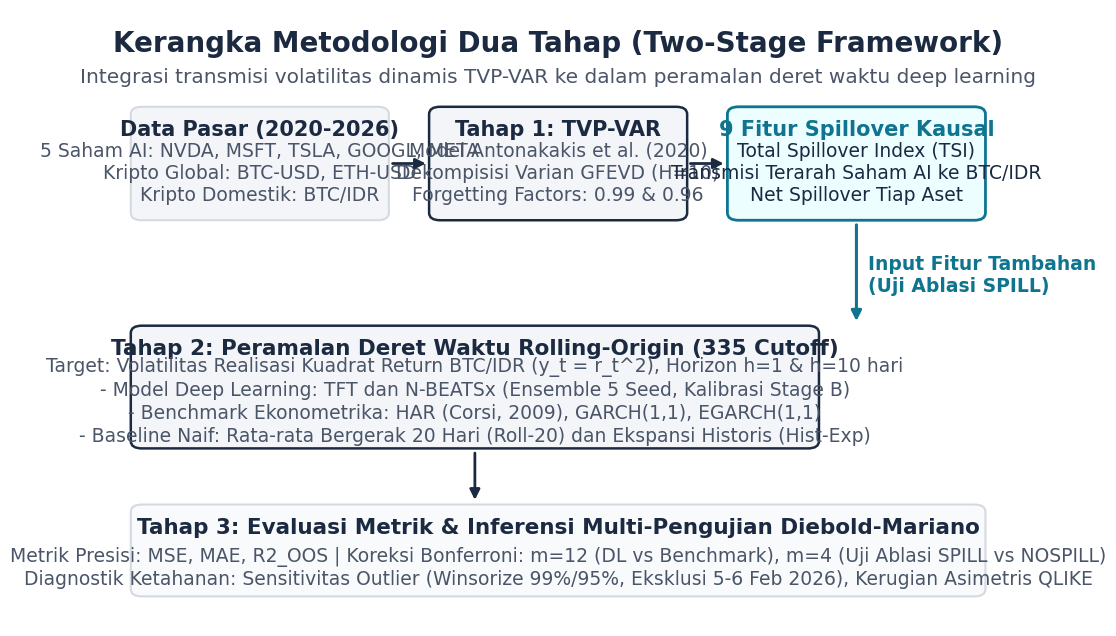

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


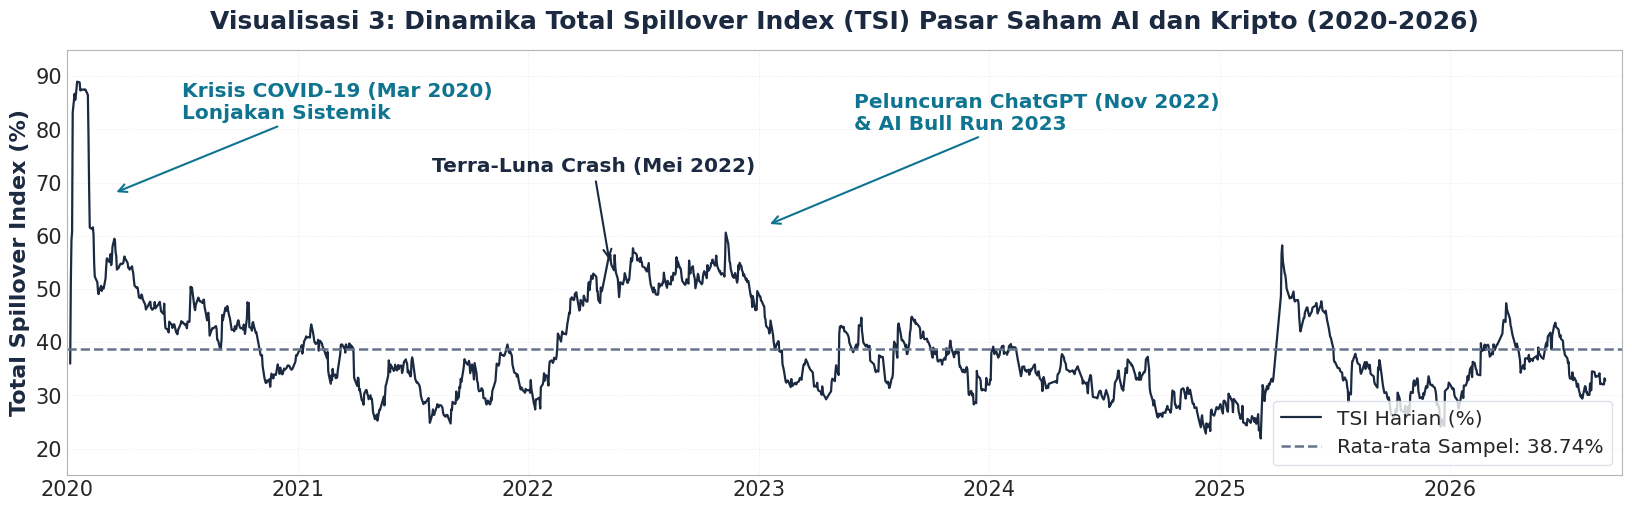

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


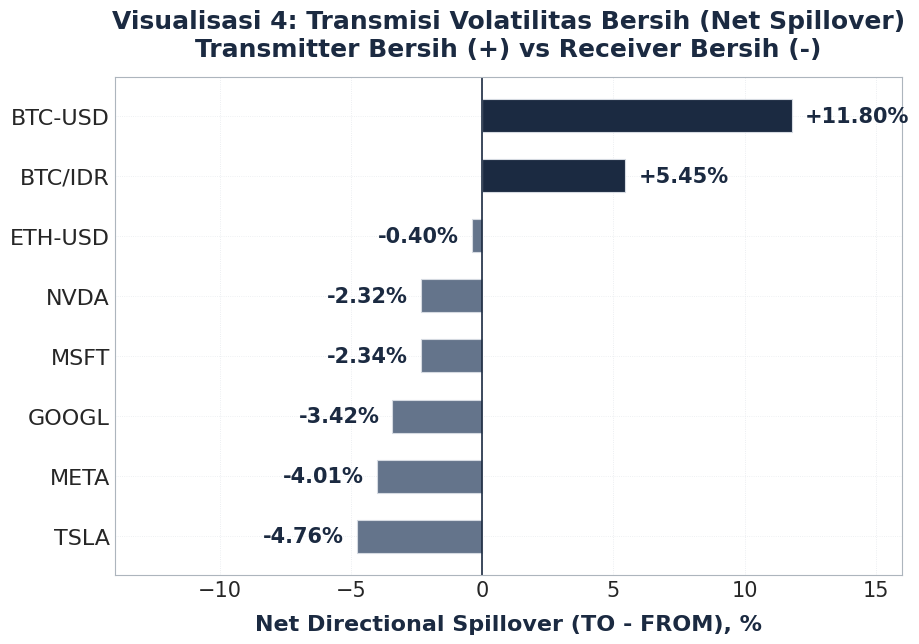

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


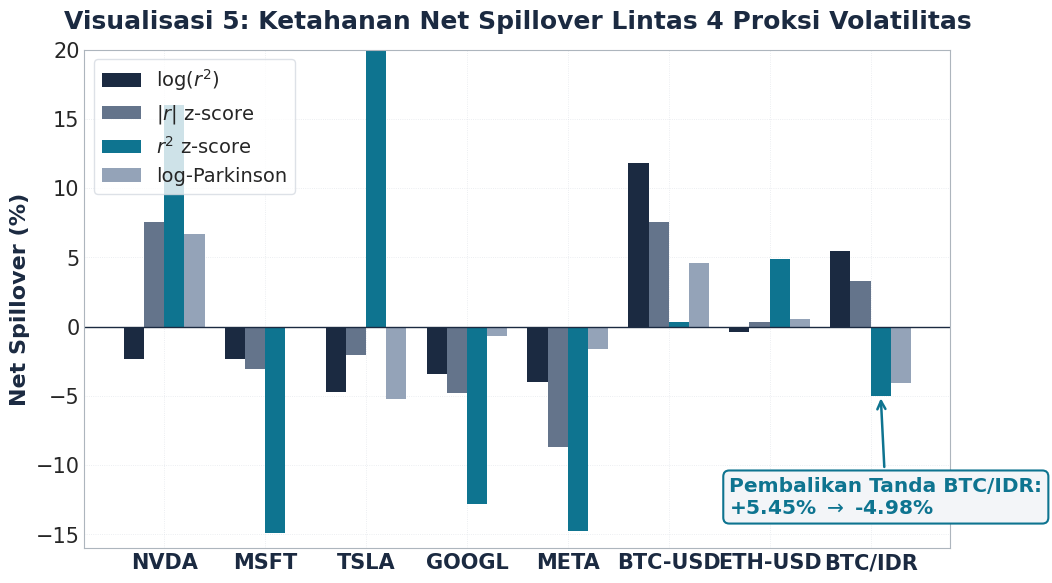

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


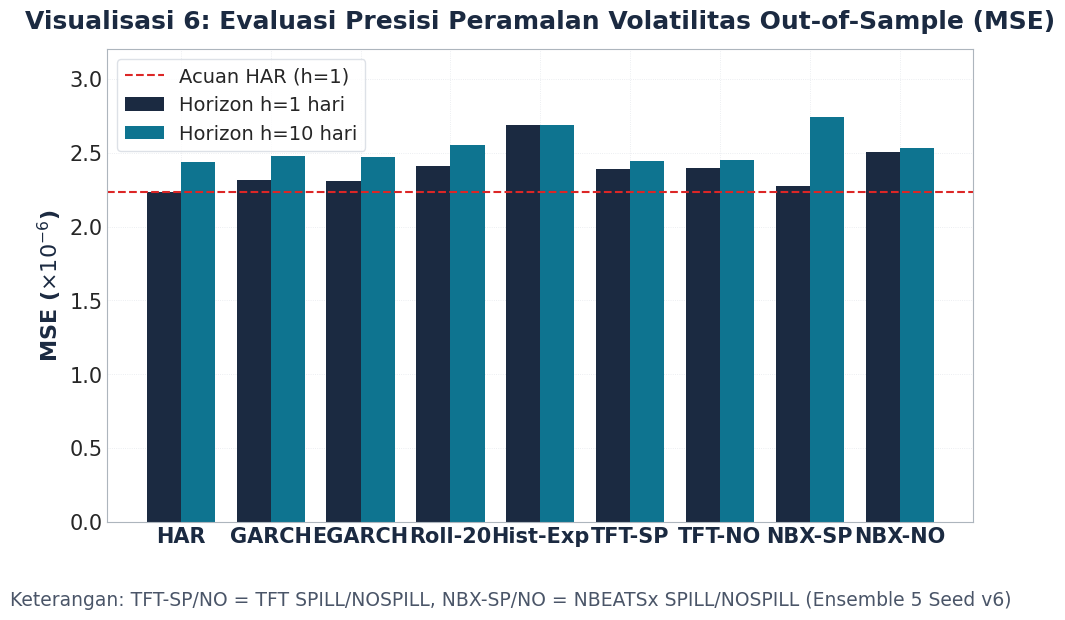

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


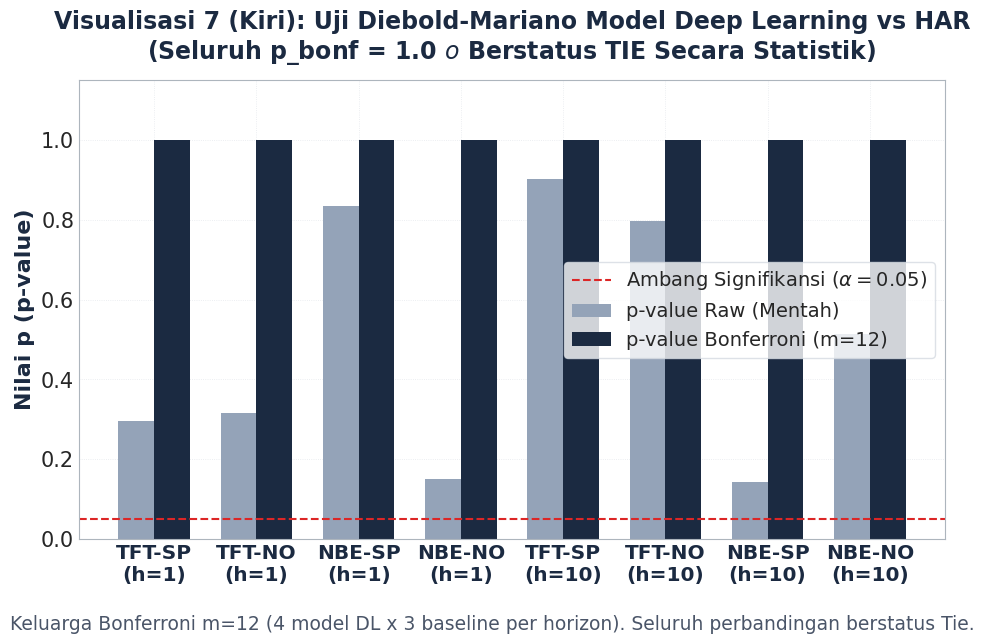

/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


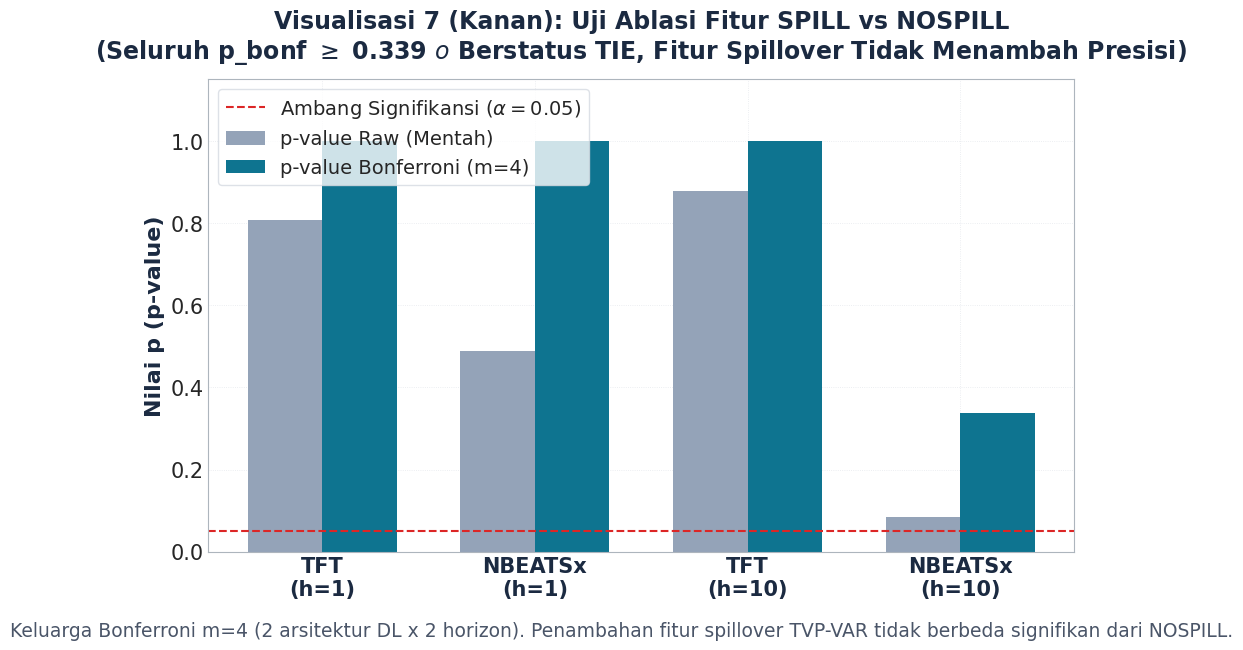

In [35]:
# ==============================================================================
# PENYAJIAN 7 VISUALISASI DENGAN STANDAR SLIDE (TATA LETAK JERNIH)
# ==============================================================================

# 1. two_stage.png (Visualisasi 1, Default 984 x 656)
fig_v1 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v1 = fig_v1.add_axes([0.03, 0.03, 0.94, 0.94])
ax_v1.set_xlim(0, 100); ax_v1.set_ylim(0, 100); ax_v1.axis('off')
ax_v1.text(50, 94.5, "Kerangka Metodologi Dua Tahap (Two-Stage Framework)", ha='center', va='center', fontsize=20, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v1.text(50, 89.0, "Integrasi transmisi volatilitas dinamis TVP-VAR ke dalam peramalan deret waktu deep learning", ha='center', va='center', fontsize=14.5, color=SLIDE_PALETTE['gray_text'])
ax_v1.add_patch(patches.FancyBboxPatch((4.0, 66.0), 27.5, 18.0, boxstyle="round,pad=0.2,rounding_size=1.2", facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['line'], linewidth=1.5))
ax_v1.text(17.75, 80.5, "Data Pasar (2020-2026)", ha='center', va='center', fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v1.text(17.75, 73.5, "5 Saham AI: NVDA, MSFT, TSLA, GOOGL, META\nKripto Global: BTC-USD, ETH-USD\nKripto Domestik: BTC/IDR", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'], linespacing=1.2)
ax_v1.add_patch(patches.FancyBboxPatch((36.25, 66.0), 27.5, 18.0, boxstyle="round,pad=0.2,rounding_size=1.2", facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['navy'], linewidth=1.8))
ax_v1.text(50.0, 80.5, "Tahap 1: TVP-VAR", ha='center', va='center', fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v1.text(50.0, 73.5, "Model Antonakakis et al. (2020)\nDekompisisi Varian GFEVD (H=10)\nForgetting Factors: 0.99 & 0.96", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'], linespacing=1.2)
ax_v1.add_patch(patches.FancyBboxPatch((68.5, 66.0), 27.5, 18.0, boxstyle="round,pad=0.2,rounding_size=1.2", facecolor='#ECFEFF', edgecolor=SLIDE_PALETTE['accent'], linewidth=2.0))
ax_v1.text(82.25, 80.5, "9 Fitur Spillover Kausal", ha='center', va='center', fontsize=15, fontweight='bold', color=SLIDE_PALETTE['accent'])
ax_v1.text(82.25, 73.5, "Total Spillover Index (TSI)\nTransmisi Terarah Saham AI ke BTC/IDR\nNet Spillover Tiap Aset", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['navy'], linespacing=1.2)
ax_v1.annotate('', xy=(36.0, 75.0), xytext=(31.8, 75.0), arrowprops=dict(arrowstyle="-|>", color=SLIDE_PALETTE['navy'], lw=2.0))
ax_v1.annotate('', xy=(68.2, 75.0), xytext=(64.0, 75.0), arrowprops=dict(arrowstyle="-|>", color=SLIDE_PALETTE['navy'], lw=2.0))
ax_v1.annotate('', xy=(82.25, 49.0), xytext=(82.25, 65.5), arrowprops=dict(arrowstyle="-|>", color=SLIDE_PALETTE['accent'], lw=2.2))
ax_v1.text(83.5, 57.0, "Input Fitur Tambahan\n(Uji Ablasi SPILL)", ha='left', va='center', fontsize=13.5, fontweight='bold', color=SLIDE_PALETTE['accent'])
ax_v1.add_patch(patches.FancyBboxPatch((4.0, 29.0), 74.0, 19.5, boxstyle="round,pad=0.2,rounding_size=1.2", facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['navy'], linewidth=1.8))
ax_v1.text(41.0, 45.0, "Tahap 2: Peramalan Deret Waktu Rolling-Origin (335 Cutoff)", ha='center', va='center', fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v1.text(41.0, 36.5, "Target: Volatilitas Realisasi Kuadrat Return BTC/IDR (y_t = r_t^2), Horizon h=1 & h=10 hari\n- Model Deep Learning: TFT dan N-BEATSx (Ensemble 5 Seed, Kalibrasi Stage B)\n- Benchmark Ekonometrika: HAR (Corsi, 2009), GARCH(1,1), EGARCH(1,1)\n- Baseline Naif: Rata-rata Bergerak 20 Hari (Roll-20) dan Ekspansi Historis (Hist-Exp)", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'], linespacing=1.25)
ax_v1.annotate('', xy=(41.0, 20.0), xytext=(41.0, 28.5), arrowprops=dict(arrowstyle="-|>", color=SLIDE_PALETTE['navy'], lw=2.0))
ax_v1.add_patch(patches.FancyBboxPatch((4.0, 5.0), 92.0, 14.5, boxstyle="round,pad=0.2,rounding_size=1.2", facecolor='#F8FAFC', edgecolor=SLIDE_PALETTE['line'], linewidth=1.5))
ax_v1.text(50.0, 16.0, "Tahap 3: Evaluasi Metrik & Inferensi Multi-Pengujian Diebold-Mariano", ha='center', va='center', fontsize=15.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v1.text(50.0, 9.5, "Metrik Presisi: MSE, MAE, R2_OOS | Koreksi Bonferroni: m=12 (DL vs Benchmark), m=4 (Uji Ablasi SPILL vs NOSPILL)\nDiagnostik Ketahanan: Sensitivitas Outlier (Winsorize 99%/95%, Eksklusi 5-6 Feb 2026), Kerugian Asimetris QLIKE", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'])
plt.show()

# 2. tsi_over_time.png (Visualisasi 3, Lebar 1728 x 560)
df_tvp = pd.read_csv('data_clean/tvp_var_dynamic_features.csv')
df_tvp['dt'] = pd.to_datetime(df_tvp['Date'])
mean_tsi = df_tvp['tvp_tsi'].mean()
fig_v3 = plt.figure(figsize=(17.28, 5.60), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v3 = fig_v3.add_axes([0.06, 0.12, 0.90, 0.76])
ax_v3.plot(df_tvp['dt'], df_tvp['tvp_tsi'], color=SLIDE_PALETTE['navy'], linewidth=1.6, label='TSI Harian (%)')
ax_v3.axhline(mean_tsi, color=SLIDE_PALETTE['slate'], linestyle='--', linewidth=1.8, label=f'Rata-rata Sampel: {mean_tsi:.2f}%')
ax_v3.annotate('Krisis COVID-19 (Mar 2020)\nLonjakan Sistemik', xy=(pd.to_datetime('2020-03-15'), 68), xytext=(pd.to_datetime('2020-07-01'), 82), arrowprops=dict(facecolor=SLIDE_PALETTE['accent'], edgecolor=SLIDE_PALETTE['accent'], arrowstyle='->', lw=1.5), fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['accent'])
ax_v3.annotate('Terra-Luna Crash (Mei 2022)', xy=(pd.to_datetime('2022-05-10'), 55), xytext=(pd.to_datetime('2021-08-01'), 72), arrowprops=dict(facecolor=SLIDE_PALETTE['navy'], edgecolor=SLIDE_PALETTE['navy'], arrowstyle='->', lw=1.5), fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v3.annotate('Peluncuran ChatGPT (Nov 2022)\n& AI Bull Run 2023', xy=(pd.to_datetime('2023-01-15'), 62), xytext=(pd.to_datetime('2023-06-01'), 80), arrowprops=dict(facecolor=SLIDE_PALETTE['accent'], edgecolor=SLIDE_PALETTE['accent'], arrowstyle='->', lw=1.5), fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['accent'])
ax_v3.set_ylabel("Total Spillover Index (%)", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v3.set_title("Visualisasi 3: Dinamika Total Spillover Index (TSI) Pasar Saham AI dan Kripto (2020-2026)", fontsize=18, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v3.set_xlim(pd.to_datetime('2020-01-01'), pd.to_datetime('2026-10-01'))
ax_v3.set_ylim(15, 95)
ax_v3.xaxis.set_major_locator(mdates.YearLocator()); ax_v3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_v3.tick_params(axis='both', which='major', labelsize=15)
ax_v3.legend(loc='lower right', frameon=True, fontsize=14.5, facecolor=SLIDE_PALETTE['white'], edgecolor=SLIDE_PALETTE['line'])
ax_v3.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line'])
plt.show()

# 3. net_spillover.png (Visualisasi 4, Default 984 x 656)
# Fokus pada diagram batang Net Directional Spillover agar seluruh font >= 15pt terbaca jernih
csv_rq1 = 'results/RQ1_Average_Spillover_Table_vol.csv'
df_gfevd = pd.read_csv(csv_rq1, index_col=0)
assets = ['SAHAM_NVDA', 'SAHAM_MSFT', 'SAHAM_TSLA', 'SAHAM_GOOGL', 'SAHAM_META', 'CRYPTO_BTC_USD', 'CRYPTO_ETH_USD', 'CRYPTO_BTC_IDR_INDODAX']
labels = ['NVDA', 'MSFT', 'TSLA', 'GOOGL', 'META', 'BTC-USD', 'ETH-USD', 'BTC/IDR']
net_vals = [float(df_gfevd.loc['NET Spillover', a]) for a in assets]
df_net = pd.DataFrame({'Asset': labels, 'Net': net_vals}).sort_values('Net', ascending=True)
fig_v4 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v4 = fig_v4.add_axes([0.14, 0.12, 0.80, 0.76])
colors = [SLIDE_PALETTE['navy'] if x >= 0 else SLIDE_PALETTE['slate'] for x in df_net['Net']]
bars = ax_v4.barh(df_net['Asset'], df_net['Net'], color=colors, height=0.55, edgecolor=SLIDE_PALETTE['line'], linewidth=0.8)
ax_v4.axvline(0, color=SLIDE_PALETTE['navy'], linewidth=1.2)
ax_v4.set_xlabel("Net Directional Spillover (TO - FROM), %", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'], labelpad=10)
ax_v4.set_title("Visualisasi 4: Transmisi Volatilitas Bersih (Net Spillover)\nTransmitter Bersih (+) vs Receiver Bersih (-)", fontsize=18, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v4.tick_params(axis='y', labelsize=16); ax_v4.tick_params(axis='x', labelsize=15)
ax_v4.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line'], axis='x')
ax_v4.set_xlim(-14.0, 16.0)
for bar in bars:
    w = bar.get_width()
    val_str = f"+{w:.2f}%" if w >= 0 else f"{w:.2f}%"
    offset = 0.5 if w >= 0 else -0.5
    ha = 'left' if w >= 0 else 'right'
    ax_v4.text(w + offset, bar.get_y() + bar.get_height()/2.0, val_str, ha=ha, va='center', fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
plt.show()

# 4. proxy_sensitivity.png (Visualisasi 5, Default 984 x 656)
ckpt_file = os.path.join(SCRATCH_FINAL, 'checkpoint3a_C.txt') if 'SCRATCH_FINAL' in globals() else 'scratch/final/checkpoint3a_C.txt'
proxy_rows = []
with open(ckpt_file, 'r') as f:
    lines = f.readlines()
in_table = False
for line in lines:
    if 'Tabel NET Rata-rata per Aset berdasarkan Proxy Volatilitas:' in line:
        in_table = True
        continue
    if in_table:
        parts = line.strip().split()
        if not parts or parts[0] == 'Tanda':
            break
        if len(parts) == 5 and parts[0] in assets:
            proxy_rows.append([parts[0]] + [float(x) for x in parts[1:]])
df_proxy = pd.DataFrame(proxy_rows, columns=['Asset', 'log_r2', 'abs_r', 'r2', 'log_Parkinson'])
df_proxy['Label'] = df_proxy['Asset'].map(dict(zip(assets, labels)))
fig_v5 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v5 = fig_v5.add_axes([0.08, 0.12, 0.88, 0.76])
x = np.arange(len(df_proxy)); w = 0.20
ax_v5.bar(x - 1.5*w, df_proxy['log_r2'], w, label=r'log($r^2$)', color=SLIDE_PALETTE['navy'])
ax_v5.bar(x - 0.5*w, df_proxy['abs_r'], w, label=r'|$r$| z-score', color='#64748B')
ax_v5.bar(x + 0.5*w, df_proxy['r2'], w, label=r'$r^2$ z-score', color=SLIDE_PALETTE['accent'])
ax_v5.bar(x + 1.5*w, df_proxy['log_Parkinson'], w, label=r'log-Parkinson', color='#94A3B8')
ax_v5.axhline(0, color=SLIDE_PALETTE['navy'], linewidth=1.0)
ax_v5.set_xticks(x); ax_v5.set_xticklabels(df_proxy['Label'], fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v5.tick_params(axis='y', labelsize=15)
ax_v5.set_ylabel("Net Spillover (%)", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v5.set_title("Visualisasi 5: Ketahanan Net Spillover Lintas 4 Proksi Volatilitas", fontsize=18, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v5.legend(frameon=True, fontsize=14, loc='upper left', facecolor=SLIDE_PALETTE['white'], edgecolor=SLIDE_PALETTE['line'])
ax_v5.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line']); ax_v5.set_ylim(-16, 20)
ax_v5.annotate(r'Pembalikan Tanda BTC/IDR:' + '\n' + r'+5.45% $\to$ -4.98%', xy=(7 + 0.5*w, -4.98), xytext=(5.6, -13.5),
               arrowprops=dict(facecolor=SLIDE_PALETTE['accent'], edgecolor=SLIDE_PALETTE['accent'], arrowstyle='->', lw=1.8),
               fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['accent'],
               bbox=dict(boxstyle='round,pad=0.3', facecolor=SLIDE_PALETTE['light_gray'], edgecolor=SLIDE_PALETTE['accent'], lw=1.5))
plt.show()

# 5. mse_mae.png (Visualisasi 6, Default 984 x 656)
ens_file = 'audit/v6/audit_v6_metrics_ensemble.csv'
df_ens = pd.read_csv(ens_file)
all_models = [
    {'Model': 'HAR', 'MSE_h1': 2.234681e-06, 'MSE_h10': 2.439743e-06},
    {'Model': 'GARCH', 'MSE_h1': 2.313042e-06, 'MSE_h10': 2.478223e-06},
    {'Model': 'EGARCH', 'MSE_h1': 2.308726e-06, 'MSE_h10': 2.474665e-06},
    {'Model': 'Roll-20', 'MSE_h1': 2.407078e-06, 'MSE_h10': 2.555685e-06},
    {'Model': 'Hist-Exp', 'MSE_h1': 2.689570e-06, 'MSE_h10': 2.686277e-06},
    {'Model': 'TFT-SP', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                         'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0])},
    {'Model': 'TFT-NO', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                         'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0])},
    {'Model': 'NBX-SP', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                         'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0])},
    {'Model': 'NBX-NO', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                         'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0])}
]
df_perf = pd.DataFrame(all_models)
fig_v6 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v6 = fig_v6.add_axes([0.09, 0.16, 0.88, 0.72])
x = np.arange(len(df_perf)); w = 0.38
ax_v6.bar(x - w/2, df_perf['MSE_h1']*1e6, w, label='Horizon h=1 hari', color=SLIDE_PALETTE['navy'])
ax_v6.bar(x + w/2, df_perf['MSE_h10']*1e6, w, label='Horizon h=10 hari', color=SLIDE_PALETTE['accent'])
ax_v6.axhline(df_perf.loc[0, 'MSE_h1']*1e6, color='#DC2626', linestyle='--', linewidth=1.5, label='Acuan HAR (h=1)')
ax_v6.set_xticks(x); ax_v6.set_xticklabels(df_perf['Model'], fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v6.tick_params(axis='y', labelsize=15)
ax_v6.set_ylabel(r"MSE ($\times 10^{-6}$)", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v6.set_title("Visualisasi 6: Evaluasi Presisi Peramalan Volatilitas Out-of-Sample (MSE)", fontsize=18, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v6.legend(frameon=True, fontsize=14, loc='upper left', facecolor=SLIDE_PALETTE['white'], edgecolor=SLIDE_PALETTE['line'])
ax_v6.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line']); ax_v6.set_ylim(0, 3.2)
fig_v6.text(0.5, 0.04, "Keterangan: TFT-SP/NO = TFT SPILL/NOSPILL, NBX-SP/NO = NBEATSx SPILL/NOSPILL (Ensemble 5 Seed v6)", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'])
plt.show()

# 6. pvalue_bonferroni.png (Visualisasi 7 Kiri, Default 984 x 656)
dm_file = 'audit/v6/audit_v6_dm_ensemble.csv'
df_dm = pd.read_csv(dm_file)
df_dm_har = df_dm[df_dm['Benchmark'].str.contains('HAR', na=False)].copy()
fig_v7a = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v7a = fig_v7a.add_axes([0.08, 0.18, 0.88, 0.70])
x = np.arange(len(df_dm_har)); w = 0.35
ax_v7a.bar(x - w/2, df_dm_har['p_raw'], width=w, color='#94A3B8', label='p-value Raw (Mentah)')
ax_v7a.bar(x + w/2, df_dm_har['p_bonf'], width=w, color=SLIDE_PALETTE['navy'], label='p-value Bonferroni (m=12)')
ax_v7a.axhline(0.05, color='#DC2626', linestyle='--', linewidth=1.5, label=r'Ambang Signifikansi ($\alpha=0.05$)')
ax_v7a.set_xticks(x)
labels_har = [f"{r['Model'][:3]}-{r['FeatureSet'][:2]}\n({r['Horizon']})" for _, r in df_dm_har.iterrows()]
ax_v7a.set_xticklabels(labels_har, fontsize=14.5, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v7a.tick_params(axis='y', labelsize=15)
ax_v7a.set_ylabel("Nilai p (p-value)", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v7a.set_title("Visualisasi 7 (Kiri): Uji Diebold-Mariano Model Deep Learning vs HAR\n(Seluruh p_bonf = 1.0 $\to$ Berstatus TIE Secara Statistik)", fontsize=17, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v7a.legend(frameon=True, fontsize=14, loc='center right', facecolor=SLIDE_PALETTE['white'], edgecolor=SLIDE_PALETTE['line'])
ax_v7a.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line']); ax_v7a.set_ylim(0, 1.15)
fig_v7a.text(0.5, 0.05, "Keluarga Bonferroni m=12 (4 model DL x 3 baseline per horizon). Seluruh perbandingan berstatus Tie.", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'])
plt.show()

# 7. pvalue_ablation.png (Visualisasi 7 Kanan, Default 984 x 656)
df_dm_abl = df_dm[df_dm['Comparison_Type'] == 'Ablation_SPILL_vs_NOSPILL'].copy()
fig_v7b = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=SLIDE_PALETTE['white'])
ax_v7b = fig_v7b.add_axes([0.08, 0.16, 0.88, 0.72])
x = np.arange(len(df_dm_abl)); w = 0.35
ax_v7b.bar(x - w/2, df_dm_abl['p_raw'], width=w, color='#94A3B8', label='p-value Raw (Mentah)')
ax_v7b.bar(x + w/2, df_dm_abl['p_bonf'], width=w, color=SLIDE_PALETTE['accent'], label='p-value Bonferroni (m=4)')
ax_v7b.axhline(0.05, color='#DC2626', linestyle='--', linewidth=1.5, label=r'Ambang Signifikansi ($\alpha=0.05$)')
ax_v7b.set_xticks(x)
labels_abl = [f"{r['Model']}\n({r['Horizon']})" for _, r in df_dm_abl.iterrows()]
ax_v7b.set_xticklabels(labels_abl, fontsize=15, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v7b.tick_params(axis='y', labelsize=15)
ax_v7b.set_ylabel("Nilai p (p-value)", fontsize=16, fontweight='bold', color=SLIDE_PALETTE['navy'])
ax_v7b.set_title("Visualisasi 7 (Kanan): Uji Ablasi Fitur SPILL vs NOSPILL\n(Seluruh p_bonf $\geq$ 0.339 $\to$ Berstatus TIE, Fitur Spillover Tidak Menambah Presisi)", fontsize=17, fontweight='bold', pad=15, color=SLIDE_PALETTE['navy'])
ax_v7b.legend(frameon=True, fontsize=14, loc='upper left', facecolor=SLIDE_PALETTE['white'], edgecolor=SLIDE_PALETTE['line'])
ax_v7b.grid(True, linestyle=':', alpha=0.6, color=SLIDE_PALETTE['line']); ax_v7b.set_ylim(0, 1.15)
fig_v7b.text(0.5, 0.04, "Keluarga Bonferroni m=4 (2 arsitektur DL x 2 horizon). Penambahan fitur spillover TVP-VAR tidak berbeda signifikan dari NOSPILL.", ha='center', va='center', fontsize=13.5, color=SLIDE_PALETTE['gray_text'])
plt.show()
